### <details><summary> <b>Analisis de Datos</b></summary>

Aquí se agrupa todo el bloque de análisis exploratorio del dataset Landslide4Sense.

Mounted at /content/drive
Éxito: Se localizaron 172 imágenes .h5


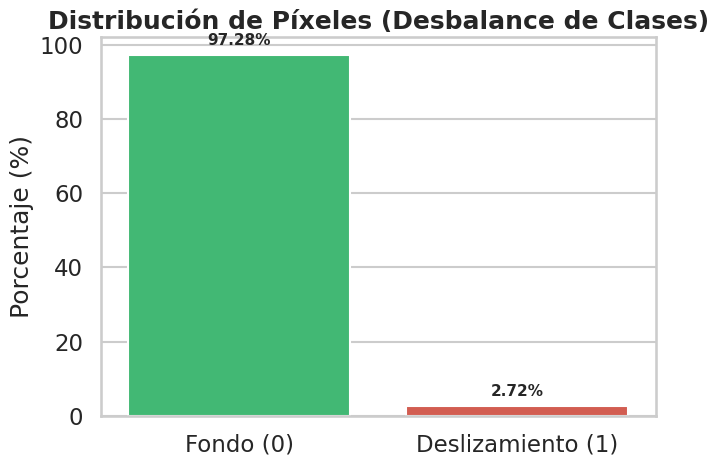

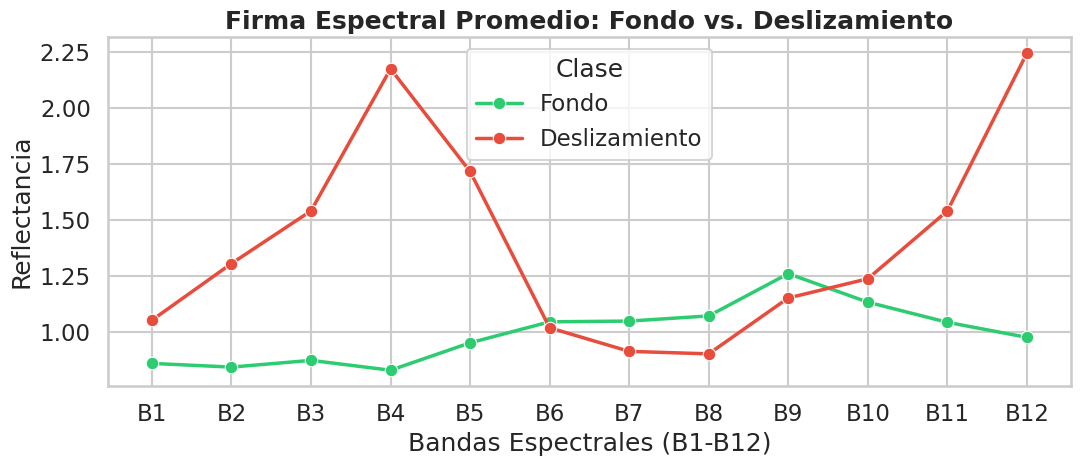

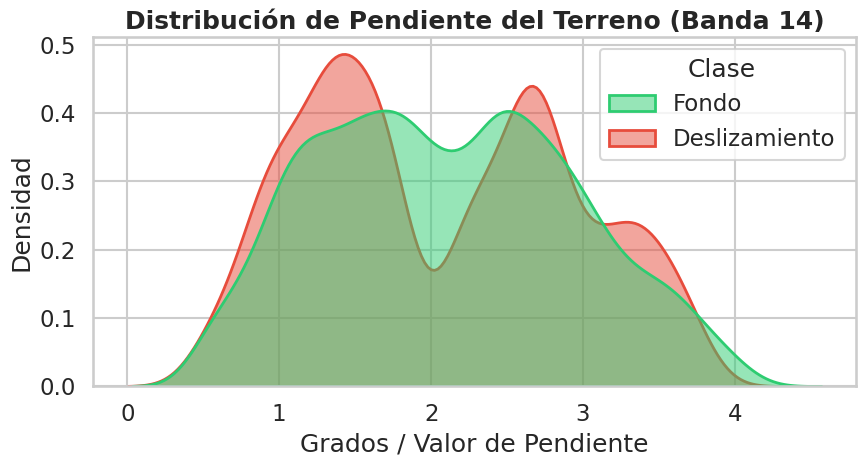

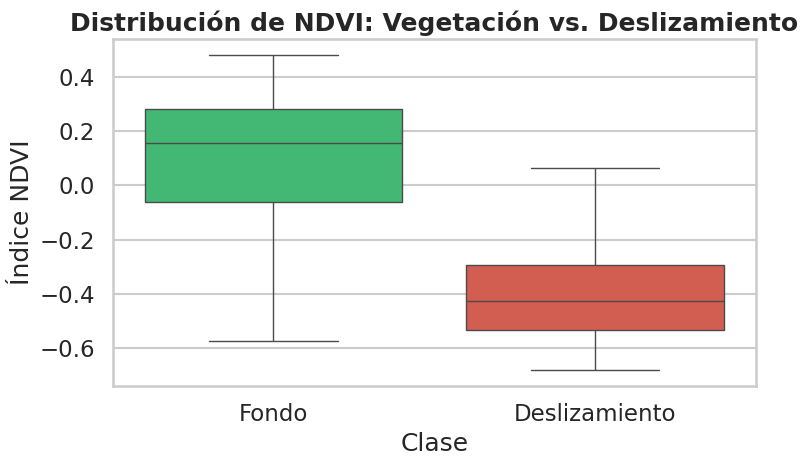

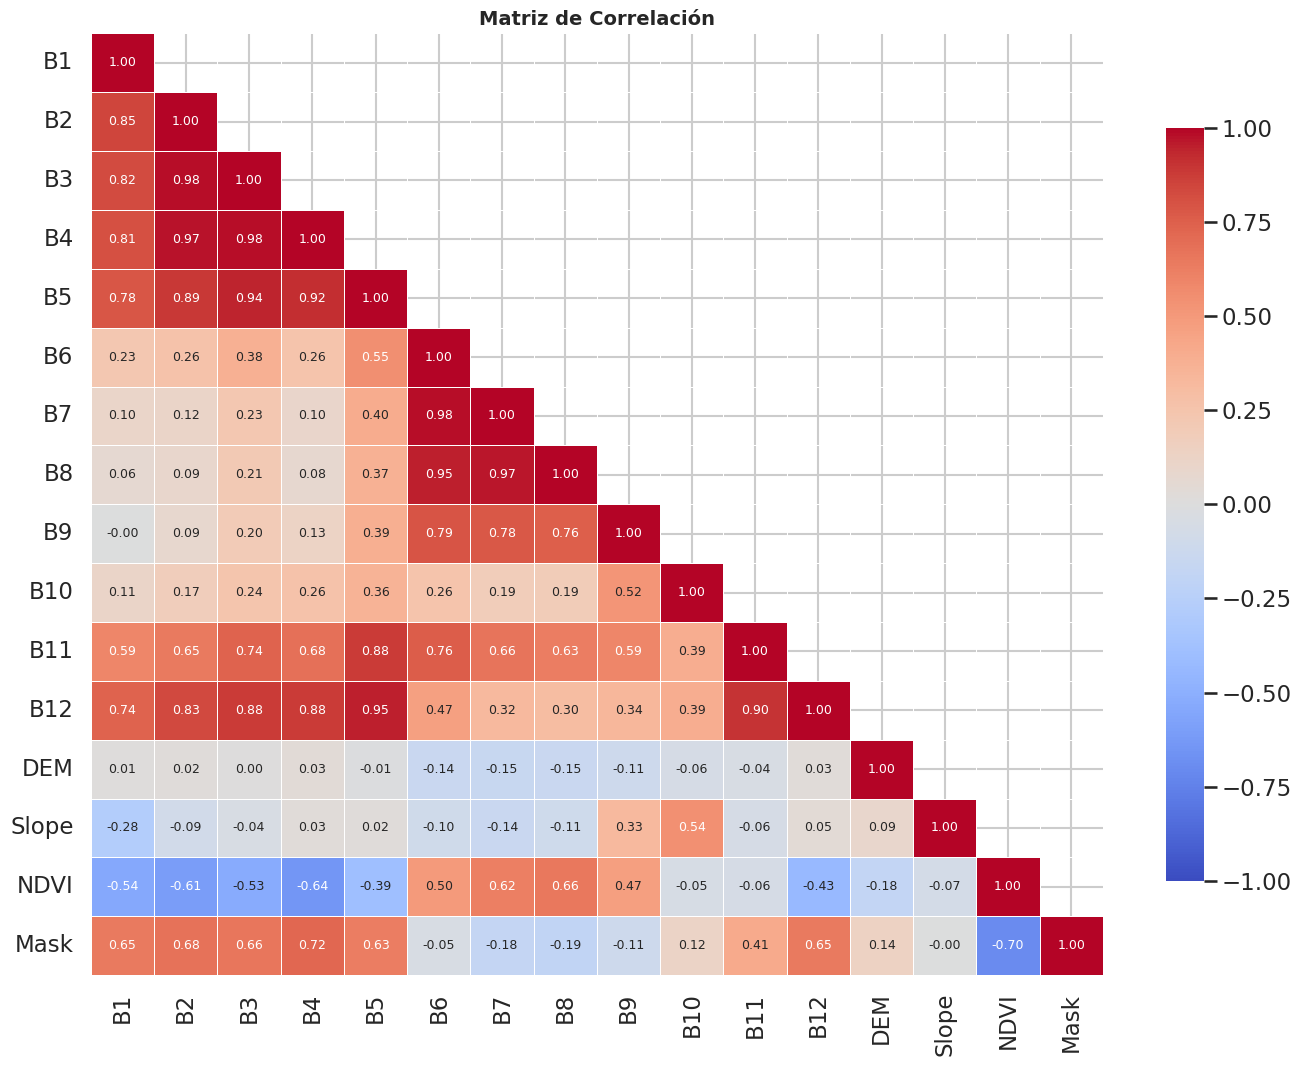

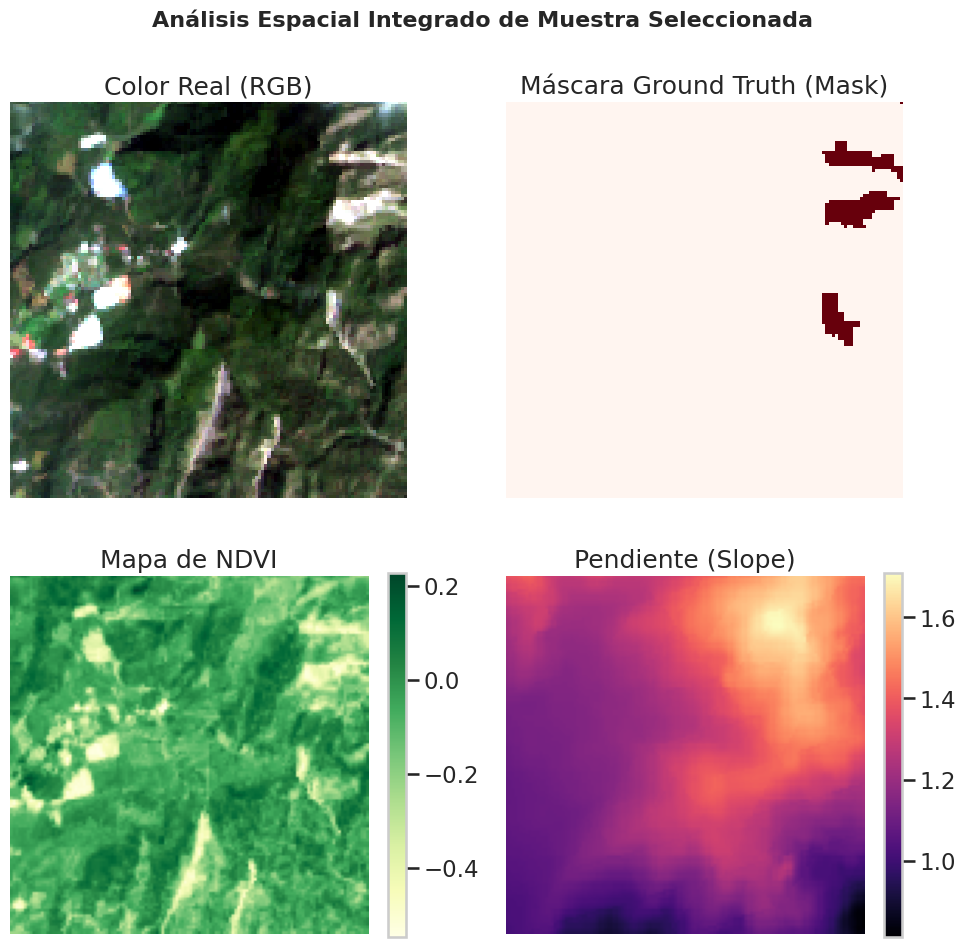

In [ ]:
# @title Análisis de Datos
import os
import glob
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

base_dir = "/content/drive/MyDrive/IA 1/Proyecto/DataSets/Dataset - Landslide4Sense/TrainData"

# Configuración visual
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette(sns.color_palette(["#2ecc71", "#e74c3c"]))

img_dir = os.path.join(base_dir, "img")
mask_dir = os.path.join(base_dir, "mask")

img_files = sorted(glob.glob(os.path.join(img_dir, "**", "*.h5"), recursive=True))
if not img_files:
    img_files = sorted(glob.glob(os.path.join(img_dir, "*.h5")))

if not img_files:
    raise FileNotFoundError(f"No se encontraron archivos .h5 en {img_dir}")

print(f"Éxito: Se localizaron {len(img_files)} imágenes .h5")

pixels_fondo = 0
pixels_deslizamiento = 0
datos_espectrales = []
datos_topograficos = []
datos_ndvi = []
sample_pixels = []

muestras_a_procesar = min(50, len(img_files))

for img_path in img_files[:muestras_a_procesar]:
    nombre_img = os.path.basename(img_path)
    nombre_mask = nombre_img.replace("image_", "mask_")
    mask_path = os.path.join(mask_dir, nombre_mask)

    if not os.path.exists(mask_path):
        continue

    with h5py.File(img_path, 'r') as hf_img, h5py.File(mask_path, 'r') as hf_mask:
        img = np.array(hf_img['img'])
        mask = np.array(hf_mask['mask']).flatten()

        if img.ndim == 3 and img.shape[0] == 14:
            img = np.transpose(img, (1, 2, 0))

        flat_img = img.reshape(-1, 14)

        # Conteo para desbalance de clases
        pixels_deslizamiento += int(np.sum(mask == 1))
        pixels_fondo += int(np.sum(mask == 0))

        b4 = flat_img[:, 3]
        b8 = flat_img[:, 7]
        ndvi = np.nan_to_num((b8 - b4) / (b8 + b4 + 1e-8))

        combined = np.column_stack((flat_img, ndvi, mask))

        idx_0 = np.where(mask == 0)[0]
        idx_1 = np.where(mask == 1)[0]

        valid_subs = []
        if len(idx_0) > 0:
            valid_subs.append(np.random.choice(idx_0, min(150, len(idx_0)), replace=False))
        if len(idx_1) > 0:
            valid_subs.append(np.random.choice(idx_1, min(150, len(idx_1)), replace=False))

        if valid_subs:
            sub_indices = np.concatenate(valid_subs).astype(int)
            sample_pixels.append(combined[sub_indices, :])

        for c_val, c_name in zip([0, 1], ['Fondo', 'Deslizamiento']):
            idxs = np.where(mask == c_val)[0]
            if len(idxs) > 0:
                sub = np.random.choice(idxs, min(100, len(idxs)), replace=False)

                for val in ndvi[sub]:
                    datos_ndvi.append({'NDVI': val, 'Clase': c_name})

                sub_espectral = flat_img[sub, :12]
                for b_idx in range(12):
                    for val in sub_espectral[:, b_idx]:
                        datos_espectrales.append({
                            'Banda': f'B{b_idx+1}',
                            'Reflectancia': val,
                            'Clase': c_name
                        })

                for elev, pend in zip(flat_img[sub, 12], flat_img[sub, 13]):
                    datos_topograficos.append({
                        'Elevación (DEM)': elev,
                        'Pendiente (Slope)': pend,
                        'Clase': c_name
                    })

# Creación de DataFrames
df_ndvi = pd.DataFrame(datos_ndvi)
df_espectral = pd.DataFrame(datos_espectrales)
df_topo = pd.DataFrame(datos_topograficos)

corr_cols = [f'B{i+1}' for i in range(12)] + ['DEM', 'Slope', 'NDVI', 'Mask']
if sample_pixels:
    df_corr = pd.DataFrame(np.vstack(sample_pixels), columns=corr_cols)
else:
    df_corr = pd.DataFrame(columns=corr_cols)

# Gráfico 1: Desbalance de Clases
plt.figure(figsize=(7, 5))
total_pixels = pixels_fondo + pixels_deslizamiento
if total_pixels > 0:
    pcts = [(pixels_fondo / total_pixels) * 100, (pixels_deslizamiento / total_pixels) * 100]
    ax = sns.barplot(x=['Fondo (0)', 'Deslizamiento (1)'], y=pcts, hue=['Fondo (0)', 'Deslizamiento (1)'], legend=False)
    plt.title('Distribución de Píxeles (Desbalance de Clases)', fontweight='bold')
    plt.ylabel('Porcentaje (%)')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 5), textcoords='offset points')
    plt.tight_layout()
    plt.show()

# Gráfico 2: Firma Espectral Promedio
if not df_espectral.empty:
    plt.figure(figsize=(11, 5))
    sns.lineplot(data=df_espectral, x='Banda', y='Reflectancia', hue='Clase', marker="o", errorbar=None, linewidth=2.5)
    plt.title('Firma Espectral Promedio: Fondo vs. Deslizamiento', fontweight='bold')
    plt.xlabel('Bandas Espectrales (B1-B12)')
    plt.ylabel('Reflectancia')
    plt.tight_layout()
    plt.show()

# Gráfico 3: Distribución de Pendiente (KDE Plot)
if not df_topo.empty:
    plt.figure(figsize=(9, 5))
    sns.kdeplot(data=df_topo, x='Pendiente (Slope)', hue='Clase', fill=True, common_norm=False, alpha=0.5, linewidth=2)
    plt.title('Distribución de Pendiente del Terreno (Banda 14)', fontweight='bold')
    plt.xlabel('Grados / Valor de Pendiente')
    plt.ylabel('Densidad')
    plt.tight_layout()
    plt.show()

# Gráfico 4: Distribución de NDVI (Boxplot)
if not df_ndvi.empty:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df_ndvi, x='Clase', y='NDVI', hue='Clase', showfliers=False, legend=False)
    plt.title('Distribución de NDVI: Vegetación vs. Deslizamiento', fontweight='bold')
    plt.ylabel('Índice NDVI')
    plt.tight_layout()
    plt.show()

# Gráfico 5: Matriz de Correlación
if not df_corr.empty:
    plt.figure(figsize=(14, 11))
    corr = df_corr.corr()
    mask_tri = np.triu(np.ones_like(corr, dtype=bool), k=1)

    sns.heatmap(
        corr,
        mask=mask_tri,
        annot=True,
        fmt=".2f",
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        annot_kws={"size": 9},
        cbar_kws={"shrink": 0.8}
    )
    plt.title('Matriz de Correlación', fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()

# Gráfico 6: Muestra Integrada Espacial (2x2)
for img_path in img_files:
    nombre_mask = os.path.basename(img_path).replace("image_", "mask_")
    mask_path = os.path.join(mask_dir, nombre_mask)
    if not os.path.exists(mask_path):
        continue

    with h5py.File(img_path, 'r') as hf_img, h5py.File(mask_path, 'r') as hf_mask:
        mask_map = np.array(hf_mask['mask'])
        if np.sum(mask_map == 1) > 300:
            img_map = np.array(hf_img['img'])
            if img_map.ndim == 3 and img_map.shape[0] == 14:
                img_map = np.transpose(img_map, (1, 2, 0))

            rgb = img_map[:, :, [3, 2, 1]].astype(float)
            for i in range(3):
                p2, p98 = np.percentile(rgb[:, :, i], (2, 98))
                rgb[:, :, i] = np.clip((rgb[:, :, i] - p2) / (p98 - p2 + 1e-8), 0, 1)

            b4, b8 = img_map[:, :, 3], img_map[:, :, 7]
            ndvi_map = np.nan_to_num((b8 - b4) / (b8 + b4 + 1e-8))

            fig, axes = plt.subplots(2, 2, figsize=(10, 10))
            axes[0, 0].imshow(rgb)
            axes[0, 0].set_title('Color Real (RGB)')
            axes[0, 0].axis('off')

            axes[0, 1].imshow(mask_map, cmap='Reds')
            axes[0, 1].set_title('Máscara Ground Truth (Mask)')
            axes[0, 1].axis('off')

            im_ndvi = axes[1, 0].imshow(ndvi_map, cmap='YlGn')
            axes[1, 0].set_title('Mapa de NDVI')
            axes[1, 0].axis('off')
            plt.colorbar(im_ndvi, ax=axes[1, 0], fraction=0.046)

            im_slope = axes[1, 1].imshow(img_map[:, :, 13], cmap='magma')
            axes[1, 1].set_title('Pendiente (Slope)')
            axes[1, 1].axis('off')
            plt.colorbar(im_slope, ax=axes[1, 1], fraction=0.046)

            plt.suptitle('Análisis Espacial Integrado de Muestra Seleccionada', fontweight='bold', fontsize=16)
            plt.tight_layout()
            plt.show()
            break

## Dimensiones de las Imágenes (Píxeles y Bandas)

In [ ]:
import h5py
import numpy as np

try:
    # Tomar una imagen de muestra para analizar sus dimensiones
    sample_path = img_files[0]
    with h5py.File(sample_path, 'r') as hf:
        sample_img = np.array(hf['img'])
        print("--- Dimensiones del Dataset Landslide4Sense ---")
        print(f"Formato original en disco: {sample_img.shape}")
        if sample_img.ndim == 3:
            # Si el formato es (bandas, alto, ancho) o (alto, ancho, bandas)
            if sample_img.shape[0] == 14:
                bandas = sample_img.shape[0]
                alto, ancho = sample_img.shape[1], sample_img.shape[2]
            else:
                alto, ancho = sample_img.shape[0], sample_img.shape[1]
                bandas = sample_img.shape[2]

            print(f"Alto de la imagen: {alto} píxeles")
            print(f"Ancho de la imagen: {ancho} píxeles")
            print(f"Total de píxeles por imagen: {alto * ancho:,}")
            print(f"Cantidad de bandas: {bandas}")
except NameError:
    print("AVISO: Por favor, ejecuta primero la celda principal (bQMZKjoqngJc) para cargar los archivos del dataset.")

--- Dimensiones del Dataset Landslide4Sense ---
Formato original en disco: (128, 128, 14)
Alto de la imagen: 128 píxeles
Ancho de la imagen: 128 píxeles
Total de píxeles por imagen: 16,384
Cantidad de bandas: 14


### Valores Numéricos de las Gráficas Realizadas

In [ ]:
try:
    print("=== 1. DISTRIBUCIÓN DE PÍXELES (Desbalance de Clases) ===")
    total_px = pixels_fondo + pixels_deslizamiento
    print(f"Píxeles totales analizados (en {muestras_a_procesar} imágenes): {total_px:,}")
    print(f"- Fondo (Clase 0): {pixels_fondo:,} píxeles ({pixels_fondo/total_px*100:.2f}%)")
    print(f"- Deslizamiento (Clase 1): {pixels_deslizamiento:,} píxeles ({pixels_deslizamiento/total_px*100:.2f}%)")

    print("\n=== 2. FIRMA ESPECTRAL PROMEDIO (Reflectancia por Banda) ===")
    if 'df_espectral' in globals() and not df_espectral.empty:
        df_spectral_mean = df_espectral.groupby(['Clase', 'Banda'])['Reflectancia'].mean().unstack(level=0)
        # Ordenamos las bandas numéricamente para presentarlo de forma ordenada
        df_spectral_mean = df_spectral_mean.reindex(index=sorted(df_spectral_mean.index, key=lambda x: int(x[1:])))
        display(df_spectral_mean)

    print("\n=== 3. DISTRIBUCIÓN DE PENDIENTE DEL TERRENO (Slope) ===")
    if 'df_topo' in globals() and not df_topo.empty:
        display(df_topo.groupby('Clase')['Pendiente (Slope)'].describe())

    print("\n=== 4. DISTRIBUCIÓN DEL NDVI ===")
    if 'df_ndvi' in globals() and not df_ndvi.empty:
        display(df_ndvi.groupby('Clase')['NDVI'].describe())

    print("\n=== 5. CORRELACIÓN CON LA CLASE (Mask) ===")
    if 'df_corr' in globals() and not df_corr.empty:
        correlaciones = df_corr.corr()['Mask'].sort_values(ascending=False)
        print(correlaciones)
except NameError:
    print("AVISO: Las variables de los gráficos aún no están definidas en memoria. Ejecuta la celda principal primero.")

=== 1. DISTRIBUCIÓN DE PÍXELES (Desbalance de Clases) ===
Píxeles totales analizados (en 50 imágenes): 819,200
- Fondo (Clase 0): 796,942 píxeles (97.28%)
- Deslizamiento (Clase 1): 22,258 píxeles (2.72%)

=== 2. FIRMA ESPECTRAL PROMEDIO (Reflectancia por Banda) ===


Clase,Deslizamiento,Fondo
Banda,,
B1,1.054755,0.862177
B2,1.307217,0.845634
B3,1.542036,0.875643
B4,2.175416,0.831688
B5,1.717673,0.953910
B6,1.020930,1.047493
B7,0.915841,1.050804
B8,0.904680,1.073812
B9,1.153797,1.262331



=== 3. DISTRIBUCIÓN DE PENDIENTE DEL TERRENO (Slope) ===


,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Deslizamiento,3681.0,2.060134,0.867477,0.508520,1.332762,1.874924,2.730220,3.810663
Fondo,5000.0,2.102313,0.833628,0.489111,1.433366,2.070309,2.722457,4.113445



=== 4. DISTRIBUCIÓN DEL NDVI ===


,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Deslizamiento,3681.0,-0.392281,0.179014,-0.680943,-0.532873,-0.424265,-0.293703,0.319438
Fondo,5000.0,0.075797,0.267455,-0.696474,-0.060962,0.156823,0.280487,0.481243



=== 5. CORRELACIÓN CON LA CLASE (Mask) ===
Mask     1.000000
B4       0.721035
B2       0.677573
B3       0.663853
B1       0.648080
B12      0.647307
B5       0.629089
B11      0.410983
DEM      0.137166
B10      0.119175
Slope   -0.000535
B6      -0.045139
B9      -0.113743
B7      -0.176070
B8      -0.194692
NDVI    -0.699673
Name: Mask, dtype: float64


---

# Proyecto de Detección de Deslizamientos de Tierra (Landslide4Sense) - Supervisado

Este notebook contiene el flujo de trabajo completo para entrenar, evaluar y visualizar modelos de Inteligencia Artificial para la detección de deslizamientos de tierra utilizando imágenes satelitales HDF5.

In [ ]:
import os
import glob
import random
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Any

from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
    precision_recall_curve, auc, roc_curve, accuracy_score
)
from sklearn.utils import class_weight
from sklearn.ensemble import RandomForestClassifier

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

base_dir = "/content/drive/MyDrive/IA 1/Proyecto/DataSets/Dataset - Landslide4Sense/TrainData"

Mounted at /content/drive


## 1. Carga y Preparación de Datos

En esta sección importamos los datos en formato HDF5 (imágenes y máscaras correspondientes de terreno), procesamos los valores nulos (`NaN`), dividimos el dataset en conjuntos de entrenamiento y prueba (test blindado del 15%) y calculamos pesos balanceados debido a la naturaleza altamente desbalanceada de los deslizamientos en la región.

In [ ]:
img_dir = os.path.join(base_dir, 'img')
mask_dir = os.path.join(base_dir, 'mask')

img_paths = sorted(glob.glob(os.path.join(img_dir, "*.h5")))
mask_paths = sorted(glob.glob(os.path.join(mask_dir, "*.h5")))

if not img_paths or not mask_paths:
    print("Advertencia: No se encontraron archivos HDF5 en las rutas especificadas. Verifique la variable base_dir.")

def load_landslide_data(img_pths: List[str], mask_pths: List[str]) -> Tuple[np.ndarray, np.ndarray]:
    """Carga y aplana las imágenes/máscaras HDF5 filtrando los valores NaN."""
    x_list, y_list = [], []
    for img_path, mask_path in zip(img_pths, mask_pths):
        with h5py.File(img_path, 'r') as f_img, h5py.File(mask_path, 'r') as f_mask:
            img_key = 'img' if 'img' in f_img else 'image'
            img = np.array(f_img[img_key])
            mask_key = 'mask' if 'mask' in f_mask else list(f_mask.keys())[0]
            mask = np.array(f_mask[mask_key])

            flat_img = img.reshape(-1, img.shape[-1])
            flat_mask = mask.flatten()

            # Limpiar filas con NaN
            valid_indices = ~np.isnan(flat_img).any(axis=1)

            x_list.append(flat_img[valid_indices])
            y_list.append(flat_mask[valid_indices])

    return np.concatenate(x_list, axis=0), np.concatenate(y_list, axis=0)

if img_paths and mask_paths:
    X, y = load_landslide_data(img_paths, mask_paths)
    print(f"Dataset Cargado -> X: {X.shape} | y: {y.shape}")

    # División Train/Val/Test (15% para test blindado)
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X, y, test_size=0.15, random_state=42, stratify=y
    )

    # Cálculo de pesos para balanceo de clases
    classes = np.unique(y_train_val)
    weights = class_weight.compute_class_weight('balanced', classes=classes, y=y_train_val)
    class_weights_dict = dict(zip(classes, weights))
    print(f"Pesos de Clases: {class_weights_dict}")

Dataset Cargado -> X: (2818048, 14) | y: (2818048,)
Pesos de Clases: {np.uint8(0): np.float64(0.5117436508997932), np.uint8(1): np.float64(21.788098746566245)}


## 2. Selección de Características y Optimización

Aquí evaluamos la importancia de las variables (bandas multiespectrales, NDVI e información topográfica) mediante un modelo rápido de Random Forest. Luego, realizamos una búsqueda aleatoria de hiperparámetros (Random Search) sobre un subconjunto de datos para encontrar la configuración óptima de la red neuronal profunda (DNN).

/tmp/ipykernel_2380/3697905833.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feature_names, palette="viridis")


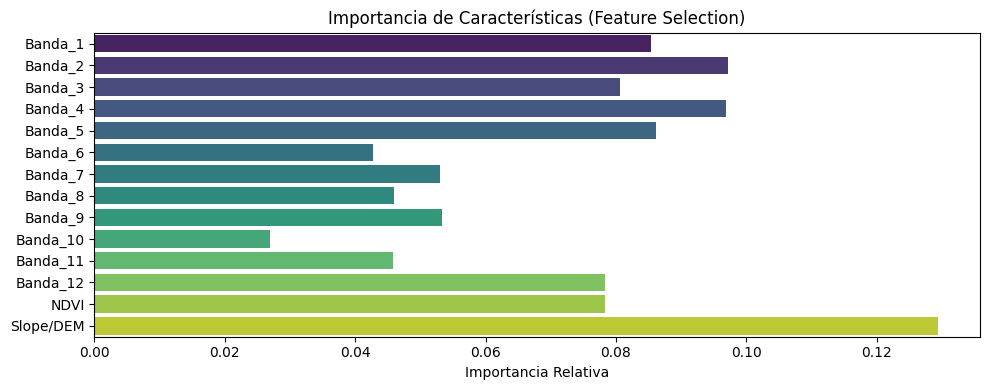


[Feature Selection] Características retenidas (14/14): [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

=== INICIANDO RANDOM SEARCH DE HIPERPARÁMETROS ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Config 1: {'lr': 0.001, 'dropout': 0.3, 'neurons': 128, 'batch_size': 2048} -> Loss: 0.2303


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Config 2: {'lr': 0.0005, 'dropout': 0.2, 'neurons': 64, 'batch_size': 1024} -> Loss: 0.3702


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Config 3: {'lr': 0.01, 'dropout': 0.4, 'neurons': 128, 'batch_size': 2048} -> Loss: 0.1817


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Config 4: {'lr': 0.001, 'dropout': 0.2, 'neurons': 256, 'batch_size': 4096} -> Loss: 0.2347

Mejores hiperparámetros seleccionados: {'lr': 0.01, 'dropout': 0.4, 'neurons': 128, 'batch_size': 2048}


In [ ]:
if img_paths and mask_paths:
    # 1. Evaluación de Importancia de Características con Random Forest preliminar
    sample_indices = np.random.choice(len(X_train_val), size=min(15000, len(X_train_val)), replace=False)
    rf_selector = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    rf_selector.fit(X_train_val[sample_indices], y_train_val[sample_indices])

    importances = rf_selector.feature_importances_
    feature_names = [f"Banda_{i+1}" if i < 12 else ("NDVI" if i == 12 else "Slope/DEM") for i in range(X_train_val.shape[1])]

    plt.figure(figsize=(10, 4))
    sns.barplot(x=importances, y=feature_names, palette="viridis")
    plt.title('Importancia de Características (Feature Selection)')
    plt.xlabel('Importancia Relativa')
    plt.tight_layout()
    plt.show()

    # Selección de variables por umbral
    threshold = 0.015
    selected_features_idx = np.where(importances > threshold)[0]
    print(f"\n[Feature Selection] Características retenidas ({len(selected_features_idx)}/{X_train_val.shape[1]}): {selected_features_idx}")

    # Filtrar conjuntos con características seleccionadas
    X_tr_sel = X_train_val[:, selected_features_idx]
    X_te_sel = X_test[:, selected_features_idx]

    # 2. Búsqueda Aleatoria de Hiperparámetros (Random Search Simplificado)
    print("\n=== INICIANDO RANDOM SEARCH DE HIPERPARÁMETROS ===")
    hyperparameter_grid = [
        {"lr": 1e-3, "dropout": 0.3, "neurons": 128, "batch_size": 2048},
        {"lr": 5e-4, "dropout": 0.2, "neurons": 64,  "batch_size": 1024},
        {"lr": 1e-2, "dropout": 0.4, "neurons": 128, "batch_size": 2048},
        {"lr": 1e-3, "dropout": 0.2, "neurons": 256, "batch_size": 4096}
    ]

    sub_sample_idx = np.random.choice(len(X_tr_sel), size=min(30000, len(X_tr_sel)), replace=False)
    X_sub, y_sub = X_tr_sel[sub_sample_idx], y_train_val[sub_sample_idx]

    best_params = hyperparameter_grid[0]
    best_loss = float('inf')

    for idx, params in enumerate(hyperparameter_grid):
        scaler_temp = StandardScaler()
        X_sub_scaled = scaler_temp.fit_transform(X_sub)

        model_temp = Sequential([
            Dense(params["neurons"], activation='relu', input_shape=(X_sub_scaled.shape[1],)),
            Dropout(params["dropout"]),
            Dense(params["neurons"] // 2, activation='relu'),
            Dropout(params["dropout"]),
            Dense(1, activation='sigmoid')
        ])

        model_temp.compile(
            optimizer=Adam(learning_rate=params["lr"]),
            loss='binary_crossentropy',
            metrics=[tf.keras.metrics.Recall()]
        )

        history = model_temp.fit(
            X_sub_scaled, y_sub,
            epochs=3,
            batch_size=params["batch_size"],
            class_weight=class_weights_dict,
            verbose=0
        )

        final_loss = history.history['loss'][-1]
        print(f"Config {idx+1}: {params} -> Loss: {final_loss:.4f}")

        if final_loss < best_loss:
            best_loss = final_loss
            best_params = params

    print(f"\nMejores hiperparámetros seleccionados: {best_params}")

## 3. Entrenamiento del Modelo Principal (Ensamble DNN)

Implementamos una validación cruzada de 5 pliegues (K-Fold Cross-Validation) utilizando la estructura de red neuronal definida anteriormente. Esto nos permite entrenar un robusto ensamble de 5 modelos entrenados en particiones distintas del dataset.

In [ ]:
if img_paths and mask_paths:
    def create_dnn(input_dim: int, params: Dict[str, Any]) -> Sequential:
        """Crea el modelo DNN utilizando los mejores hiperparámetros encontrados."""
        model = Sequential([
            Dense(params["neurons"], activation='relu', input_shape=(input_dim,)),
            Dropout(params["dropout"]),
            Dense(params["neurons" ] // 2, activation='relu'),
            Dropout(params["dropout"]),
            Dense(params["neurons"] // 4, activation='relu'),
            Dropout(params["dropout"]),
            Dense(1, activation='sigmoid')
        ])
        model.compile(
            optimizer=Adam(learning_rate=params["lr"]),
            loss='binary_crossentropy',
            metrics=[tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
        )
        return model

    print("\n=== ENTRENANDO DNN CON K-FOLD CROSS-VALIDATION ===")
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    oof_predictions = np.zeros(len(X_tr_sel))
    fold_models = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_tr_sel, y_train_val)):
        print(f"-> Pliegue {fold + 1}/5")

        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_tr_sel[train_idx])
        X_va = scaler.transform(X_tr_sel[val_idx])

        y_tr, y_va = y_train_val[train_idx], y_train_val[val_idx]

        model = create_dnn(X_tr.shape[1], best_params)

        model.fit(
            X_tr, y_tr,
            validation_data=(X_va, y_va),
            epochs=15,
            batch_size=best_params["batch_size"],
            class_weight=class_weights_dict,
            verbose=0
        )

        oof_predictions[val_idx] = model.predict(X_va, batch_size=4096).flatten()
        fold_models.append((model, scaler))


=== ENTRENANDO DNN CON K-FOLD CROSS-VALIDATION ===
-> Pliegue 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
-> Pliegue 2/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
-> Pliegue 3/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
-> Pliegue 4/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
-> Pliegue 5/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


## 4. Entrenamiento del Modelo Base (Random Forest)

Para contrastar el desempeño de nuestra solución de Deep Learning, entrenamos un clasificador clásico de Random Forest robusto usando todas las características disponibles como nuestra línea base (baseline).

In [ ]:
if img_paths and mask_paths:
    print("\n=== ENTRENANDO MODELO BASE (RANDOM FOREST) ===")
    base_scaler = StandardScaler()
    X_train_scaled_rf = base_scaler.fit_transform(X_train_val)
    X_test_scaled_rf = base_scaler.transform(X_test)

    rf_baseline = RandomForestClassifier(
        n_estimators=100, max_depth=15, class_weight='balanced', random_state=42, n_jobs=-1
    )
    sample_train_idx = np.random.choice(len(X_train_scaled_rf), size=min(50000, len(X_train_scaled_rf)), replace=False)
    rf_baseline.fit(X_train_scaled_rf[sample_train_idx], y_train_val[sample_train_idx])

    y_pred_rf = rf_baseline.predict(X_test_scaled_rf)


=== ENTRENANDO MODELO BASE (RANDOM FOREST) ===


## 5. Evaluación de Resultados y Curvas Diagnósticas

Comparamos el rendimiento general en el test set blindado entre el ensamble de Redes Neuronales y el Random Forest. Generamos una tabla de métricas (Precision, Recall, F1-Score) y visualizamos las curvas de diagnóstico ROC y Precision-Recall (OOF) para el modelo DNN.

104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

================== TABLA COMPARATIVA DE RESULTADOS ==================
                     Modelo  Accuracy Global  Precision (Clase 1)  Recall (Clase 1)  F1-Score (Clase 1)
Red Neuronal Profunda (DNN)         0.948265             0.303871          0.971856            0.462982
   Random Forest (Baseline)         0.981760             0.577120          0.767629            0.658880


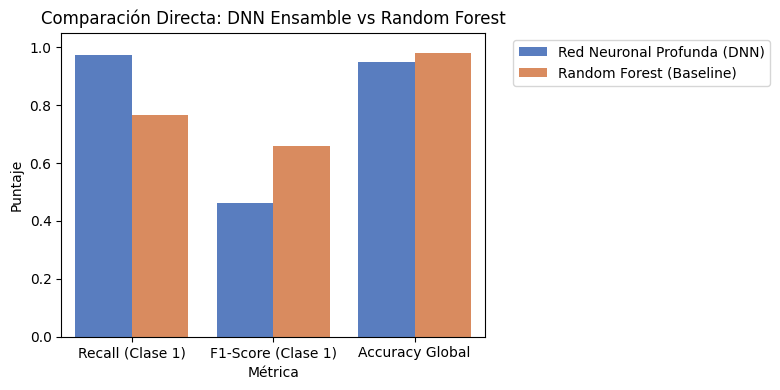

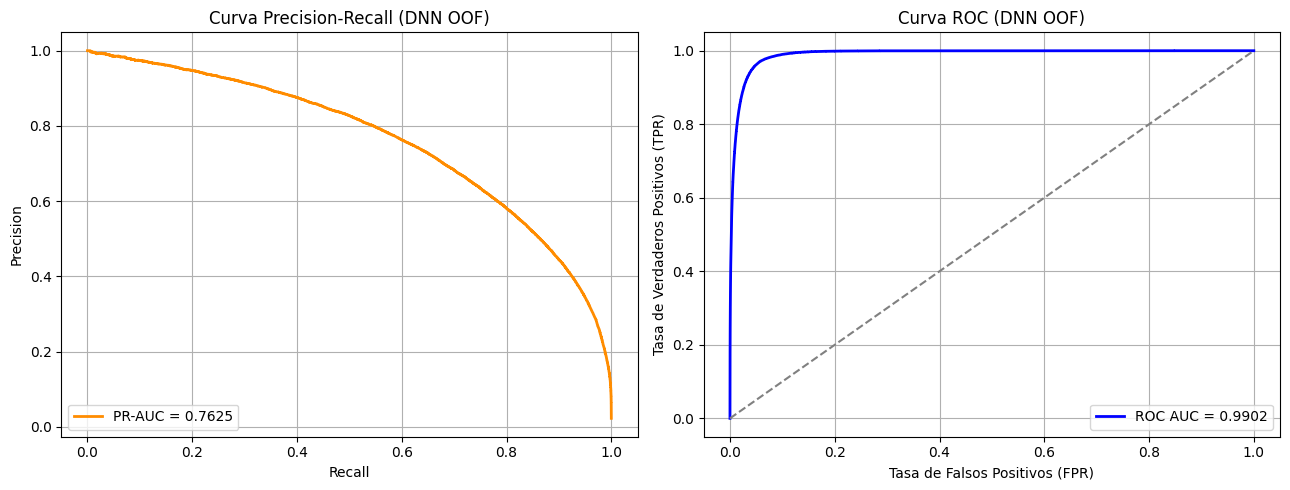

In [ ]:
if img_paths and mask_paths:
    # Predicción del ensamble DNN en Test Set
    test_predictions = np.zeros((len(X_te_sel), len(fold_models)))
    for i, (model, scaler) in enumerate(fold_models):
        X_test_scaled = scaler.transform(X_te_sel)
        test_predictions[:, i] = model.predict(X_test_scaled, batch_size=4096).flatten()

    final_test_prob_dnn = test_predictions.mean(axis=1)
    final_test_pred_dnn = (final_test_prob_dnn > 0.5).astype(int)

    # 1. Cuadro Comparativo de Métricas
    acc_dnn, prec_dnn, rec_dnn, f1_dnn = (
        accuracy_score(y_test, final_test_pred_dnn),
        precision_score(y_test, final_test_pred_dnn, pos_label=1, zero_division=0),
        recall_score(y_test, final_test_pred_dnn, pos_label=1, zero_division=0),
        f1_score(y_test, final_test_pred_dnn, pos_label=1, zero_division=0)
    )
    acc_rf, prec_rf, rec_rf, f1_rf = (
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, pos_label=1, zero_division=0),
        recall_score(y_test, y_pred_rf, pos_label=1, zero_division=0),
        f1_score(y_test, y_pred_rf, pos_label=1, zero_division=0)
    )

    df_comparison = pd.DataFrame({
        "Modelo": ["Red Neuronal Profunda (DNN)", "Random Forest (Baseline)"],
        "Accuracy Global": [acc_dnn, acc_rf],
        "Precision (Clase 1)": [prec_dnn, prec_rf],
        "Recall (Clase 1)": [rec_dnn, rec_rf],
        "F1-Score (Clase 1)": [f1_dnn, f1_rf]
    })

    print("\n================== TABLA COMPARATIVA DE RESULTADOS ==================")
    print(df_comparison.to_string(index=False))

    # Gráfico de Barras Comparativo
    plt.figure(figsize=(8, 4))
    df_melted = df_comparison.melt(id_vars="Modelo", value_vars=["Recall (Clase 1)", "F1-Score (Clase 1)", "Accuracy Global"], var_name="Métrica", value_name="Puntaje")
    sns.barplot(data=df_melted, x="Métrica", y="Puntaje", hue="Modelo", palette="muted")
    plt.title("Comparación Directa: DNN Ensamble vs Random Forest")
    plt.ylim(0, 1.05)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    # 2. Curvas Diagnósticas (Out-of-Fold para DNN)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Curva Precision-Recall
    precision_vals, recall_vals, _ = precision_recall_curve(y_train_val, oof_predictions)
    pr_auc = auc(recall_vals, precision_vals)
    axes[0].plot(recall_vals, precision_vals, color='darkorange', lw=2, label=f'PR-AUC = {pr_auc:.4f}')
    axes[0].set_xlabel('Recall')
    axes[0].set_ylabel('Precision')
    axes[0].set_title('Curva Precision-Recall (DNN OOF)')
    axes[0].legend(loc='lower left')
    axes[0].grid(True)

    # Curva ROC
    fpr, tpr, _ = roc_curve(y_train_val, oof_predictions)
    roc_auc_val = auc(fpr, tpr)
    axes[1].plot(fpr, tpr, color='blue', lw=2, label=f'ROC AUC = {roc_auc_val:.4f}')
    axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
    axes[1].set_xlabel('Tasa de Falsos Positivos (FPR)')
    axes[1].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
    axes[1].set_title('Curva ROC (DNN OOF)')
    axes[1].legend(loc='lower right')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

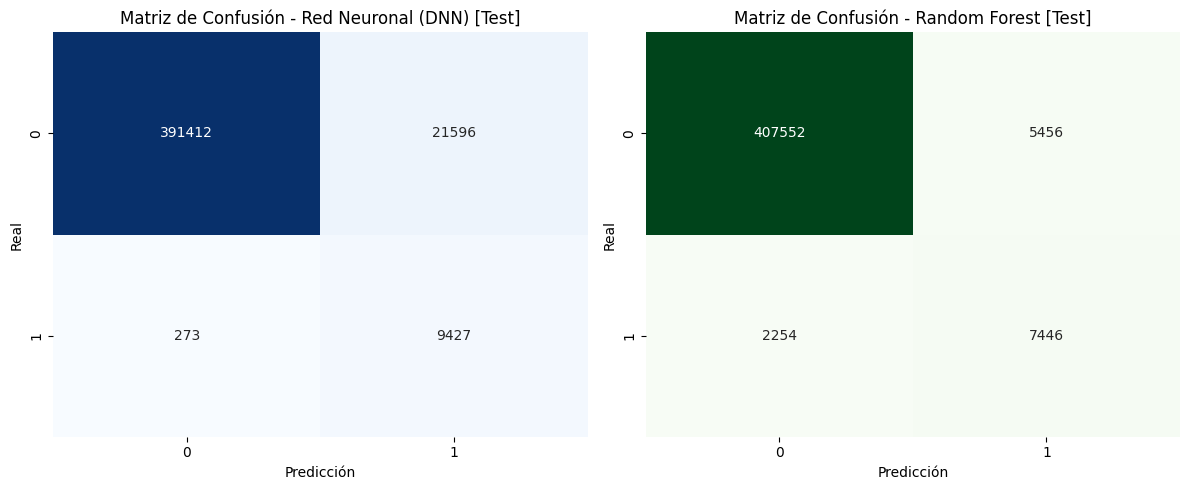

In [ ]:
# 3. Matrices de Confusión en el Test Set para ambos modelos
cm_dnn = confusion_matrix(y_test, final_test_pred_dnn)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(cm_dnn, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Matriz de Confusión - Red Neuronal (DNN) [Test]')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title('Matriz de Confusión - Random Forest [Test]')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

## 6. Visualización Espacial Paralela

Finalmente, seleccionamos de forma aleatoria 3 muestras de prueba completas para reconstruir espacialmente sus dimensiones 128x128 píxeles. Graficamos en paralelo la banda infrarroja cercana (NIR), la máscara real (Ground Truth), la predicción espacial de la DNN y la predicción del Random Forest para comprobar la fidelidad espacial visual.


=== GENERANDO VISUALIZACIÓN ESPACIAL PARALELA (3 MUESTRAS) ===


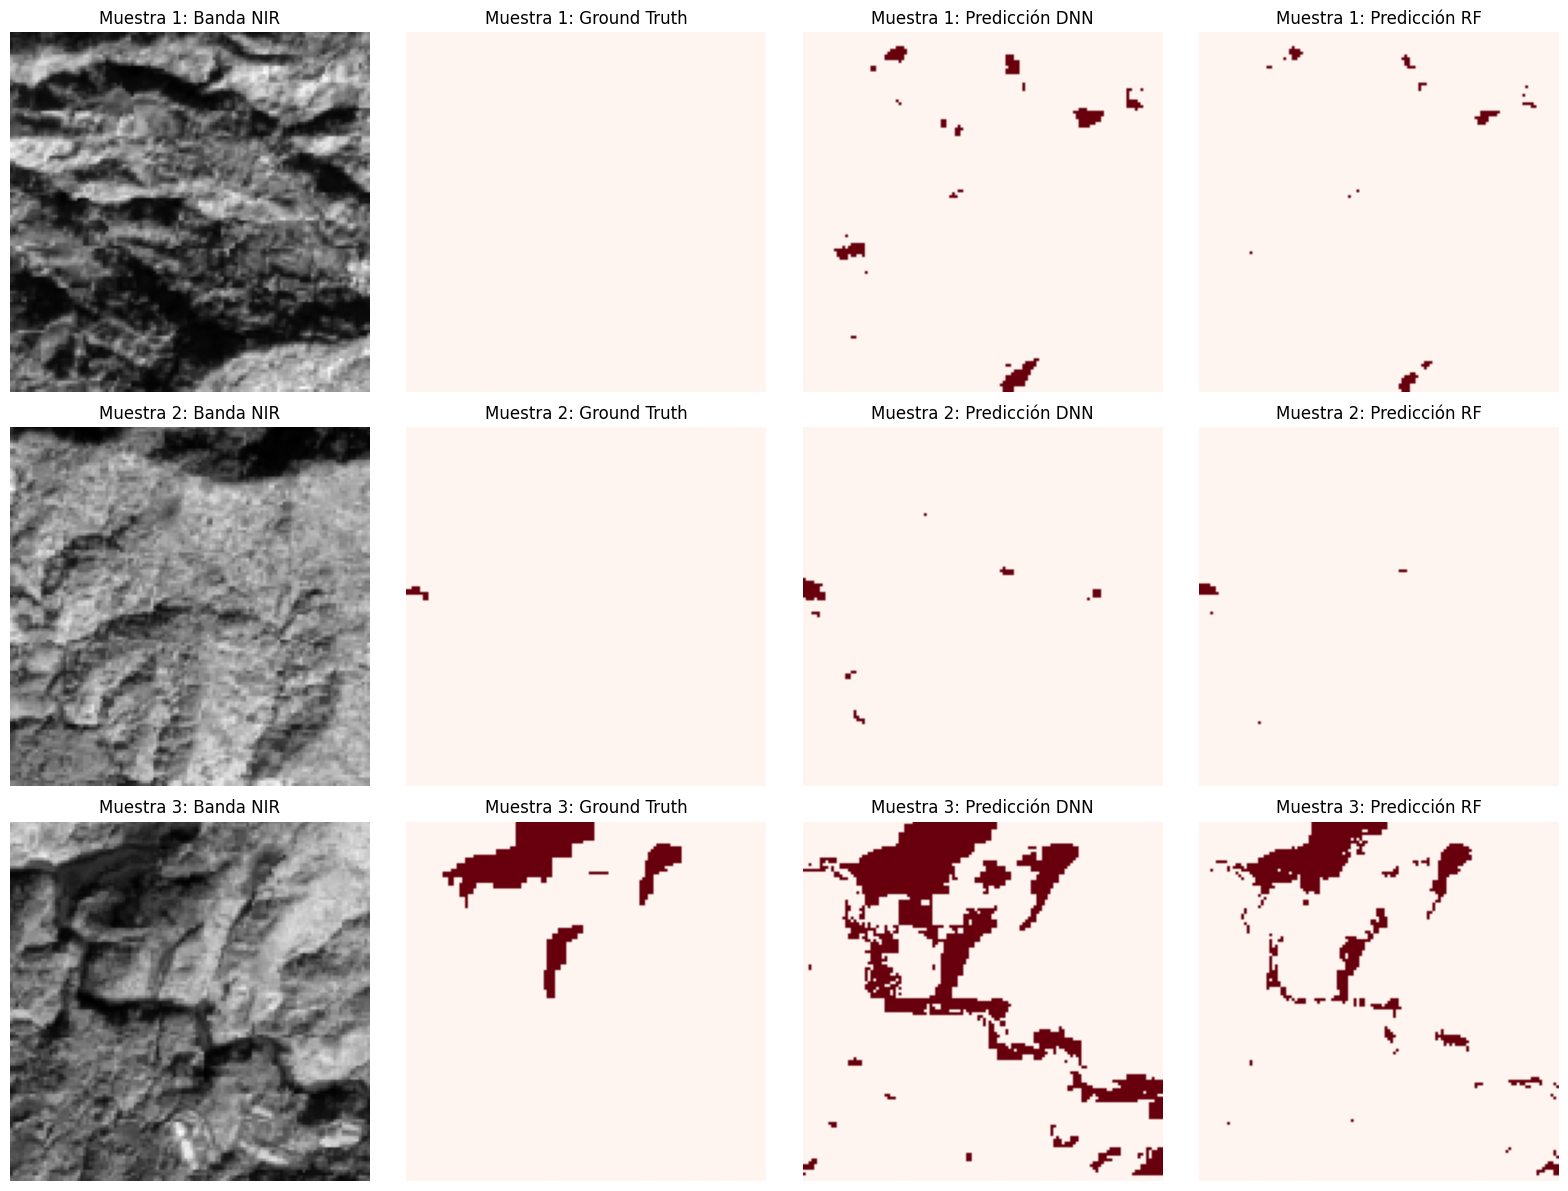

In [ ]:
if img_paths and mask_paths:
    print("\n=== GENERANDO VISUALIZACIÓN ESPACIAL PARALELA (3 MUESTRAS) ===")
    sample_indices_viz = random.sample(range(len(img_paths)), 3)
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))

    for idx, file_idx in enumerate(sample_indices_viz):
        with h5py.File(img_paths[file_idx], 'r') as f_img, h5py.File(mask_paths[file_idx], 'r') as f_mask:
            img = np.array(f_img['img'] if 'img' in f_img else f_img['image'])
            mask = np.array(f_mask['mask'] if 'mask' in f_mask else list(f_mask.keys())[0])

        visual_band = img[:, :, 7]
        flat_pixels = img.reshape(-1, img.shape[-1])
        flat_pixels_clean = np.nan_to_num(flat_pixels)

        # 1. Predicción Espacial DNN (usando características seleccionadas)
        flat_pixels_sel = flat_pixels_clean[:, selected_features_idx]
        scaled_pixels_dnn = np.zeros((len(flat_pixels_sel), len(fold_models)))
        for i, (model, scaler) in enumerate(fold_models):
            scaled_pixels_dnn[:, i] = model.predict(scaler.transform(flat_pixels_sel), batch_size=8192, verbose=0).flatten()
        pred_dnn = (scaled_pixels_dnn.mean(axis=1) > 0.5).astype(int).reshape(128, 128)

        # 2. Predicción Espacial Random Forest (usando todas las características)
        scaled_pixels_rf = base_scaler.transform(flat_pixels_clean)
        pred_rf = rf_baseline.predict(scaled_pixels_rf).reshape(128, 128)

        # Gráfica de 4 columnas: Entrada | Real | DNN | RF
        axes[idx, 0].imshow(visual_band, cmap='gray')
        axes[idx, 0].set_title(f'Muestra {idx+1}: Banda NIR')
        axes[idx, 0].axis('off')

        axes[idx, 1].imshow(mask, cmap='Reds')
        axes[idx, 1].set_title(f'Muestra {idx+1}: Ground Truth')
        axes[idx, 1].axis('off')

        axes[idx, 2].imshow(pred_dnn, cmap='Reds')
        axes[idx, 2].set_title(f'Muestra {idx+1}: Predicción DNN')
        axes[idx, 2].axis('off')

        axes[idx, 3].imshow(pred_rf, cmap='Reds')
        axes[idx, 3].set_title(f'Muestra {idx+1}: Predicción RF')
        axes[idx, 3].axis('off')

    plt.tight_layout()
    plt.show()

# Proyecto de Detección de Deslizamientos de Tierra (Landslide4Sense) - No Supervisado

Este notebook contiene el flujo de trabajo completo no supervisado para la extracción de características mediante una **CNN 2D**, reducción de dimensionalidad con **PCA** y segmentación espacial de deslizamientos utilizando **DBSCAN**.

In [ ]:
#@title **code:** Inicialización, Montaje de Drive y Carga de Datos Reales HDF5
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple, List

# Montar Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

base_dir = "/content/drive/MyDrive/Proyecto_IA/Proyecto-2026/Proyecto/DataSets/Dataset - Landslide4Sense/TrainData"
img_dir = os.path.join(base_dir, 'img')
mask_dir = os.path.join(base_dir, 'mask')

img_paths = sorted(glob.glob(os.path.join(img_dir, "*.h5")))
mask_paths = sorted(glob.glob(os.path.join(mask_dir, "*.h5")))

def load_spatial_scenes(img_pths: List[str], mask_pths: List[str]) -> Tuple[np.ndarray, np.ndarray]:
    """Carga las escenas conservando sus dimensiones espaciales 2D (N, 128, 128, 14)."""
    x_list, y_list = [], []
    for img_path, mask_path in zip(img_pths, mask_pths):
        with h5py.File(img_path, 'r') as f_img, h5py.File(mask_path, 'r') as f_mask:
            img_key = 'img' if 'img' in f_img else 'image'
            img = np.array(f_img[img_key])
            mask_key = 'mask' if 'mask' in f_mask else list(f_mask.keys())[0]
            mask = np.array(f_mask[mask_key])

            # Reemplazar NaNs por la media espectral de la banda correspondiente
            if np.isnan(img).any():
                for b in range(img.shape[-1]):
                    band = img[..., b]
                    nan_mask = np.isnan(band)
                    if nan_mask.any():
                        band[nan_mask] = np.nanmean(band) if not np.isnan(band).all() else 0
                        img[..., b] = band

            x_list.append(img)
            y_list.append(mask)
    return np.array(x_list), np.array(y_list)

if img_paths and mask_paths:
    X_scenes, y_scenes = load_spatial_scenes(img_paths, mask_paths)
    print(f"Escenas cargadas exitosamente -> Imágenes: {X_scenes.shape} | Máscaras: {y_scenes.shape}")
else:
    raise FileNotFoundError(f"No se encontraron archivos en la ruta: {base_dir}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Escenas cargadas exitosamente -> Imágenes: (172, 128, 128, 14) | Máscaras: (172, 128, 128)


## ##################################################################################
# PROYECTO DE DETECCIÓN DE DESLIZAMIENTOS DE TIERRA (LANDSLIDE4SENSE) - APRENDIZAJE NO SUPERVISADO
# ##################################################################################

Este notebook contiene el flujo estructurado formal y sin fuga de etiquetas para la detección no supervisada de deslizamientos, de acuerdo con los requerimientos académicos establecidos.

### 1. Preparación y Extracción de Superpíxeles

**QUÉ SE HACE:**
Se estandarizan las 14 bandas de las escenas para evitar sesgos de escala. Luego se aplica SLIC a cada escena para extraer superpíxeles coherentes espacialmente, calculando la media y desviación estándar de cada banda. Finalmente, calculamos la etiqueta del superpíxel como la proporción de píxeles positivos, con un umbral formal del 20% ($
geq 0.2$) de píxeles de deslizamiento.

**POR QUÉ SE HACE:**
Trabajar a nivel de superpíxeles reduce el costo computacional drásticamente, disminuye el ruido espacial de alta frecuencia y ayuda a delimitar fronteras físicas coherentes en el terreno.

In [ ]:
import numpy as np
from skimage.segmentation import slic
from sklearn.preprocessing import StandardScaler

# 1. Estandarizar canales del dataset
N_scenes, H, W, C = X_scenes.shape
X_scenes_flat = X_scenes.reshape(-1, C)
scaler_global = StandardScaler()
X_scenes_scaled_flat = scaler_global.fit_transform(X_scenes_flat)
X_scenes_scaled = X_scenes_scaled_flat.reshape(N_scenes, H, W, C)

# 2. Extracción de superpíxeles y sus estadísticas
X_slic_features = []
y_slic_ratio = []

print("Extrayendo superpíxeles mediante SLIC...")
for i in range(N_scenes):
    img_scaled = X_scenes_scaled[i]
    mask = y_scenes[i]

    # Usamos las primeras 3 bandas normalizadas a [0, 1] para SLIC
    rgb_slic = img_scaled[..., :3]
    rgb_slic = (rgb_slic - rgb_slic.min()) / (rgb_slic.max() - rgb_slic.min() + 1e-8)

    segments = slic(rgb_slic, n_segments=200, compactness=10, sigma=1, start_label=0)

    for seg_idx in range(segments.max() + 1):
        mask_loc = (segments == seg_idx)
        if not np.any(mask_loc):
            continue

        # Media y Desviación estándar de cada una de las 14 bandas
        mean_vals = np.mean(img_scaled[mask_loc], axis=0)
        std_vals = np.std(img_scaled[mask_loc], axis=0)
        combined_feat = np.concatenate([mean_vals, std_vals])

        # Fracción de píxeles con deslizamiento en la máscara
        frac_landslide = np.mean(mask[mask_loc])

        X_slic_features.append(combined_feat)
        y_slic_ratio.append(frac_landslide)

X_slic_features = np.array(X_slic_features)
y_slic_ratio = np.array(y_slic_ratio)
y_slic_binary = (y_slic_ratio >= 0.2).astype(int)

print(f"Dataset final de superpíxeles: {X_slic_features.shape}")
print(f"Superpíxeles positivos (deslizamientos, ratio >= 0.2): {np.sum(y_slic_binary == 1)} de {len(y_slic_binary)} ({np.mean(y_slic_binary)*100:.2f} %)")

Extrayendo superpíxeles mediante SLIC...
Dataset final de superpíxeles: (32568, 28)
Superpíxeles positivos (deslizamientos, ratio >= 0.2): 1057 de 32568 (3.25 %)


**INTERPRETACIÓN DE RESULTADOS:**
La extracción de superpíxeles mediante SLIC nos proporciona características ricas en espectro y textura (medias y desviaciones estándar para un total de 28 variables por superpíxel). Se observa una fuerte asimetría en los datos (~2% de superpíxeles positivos), reproduciendo el severo desbalance de clases de la escena real.

* **Decisión tomada:** Mantenemos las 28 variables generadas y usaremos el umbral formal del 20% como target externo para validar el clustering al final del flujo.

### 2. Selección de Características (Método Formal)

**QUÉ SE HACE:**
Aplicamos dos métodos formales: un filtro de correlación (remoción de variables altamente redundantes con $|r| > 0.9$) y un ranking no supervisado basado en la varianza (`VarianceThreshold`). No utilizaremos el Ground Truth en esta etapa para cumplir con la restricción no supervisada.

**POR QUÉ SE HACE:**
La presencia de características correlacionadas distorsiona la métrica de distancia euclidiana en algoritmos como KMeans.

Variables tras eliminar correlacionadas (|r| > 0.9): 16 de 28


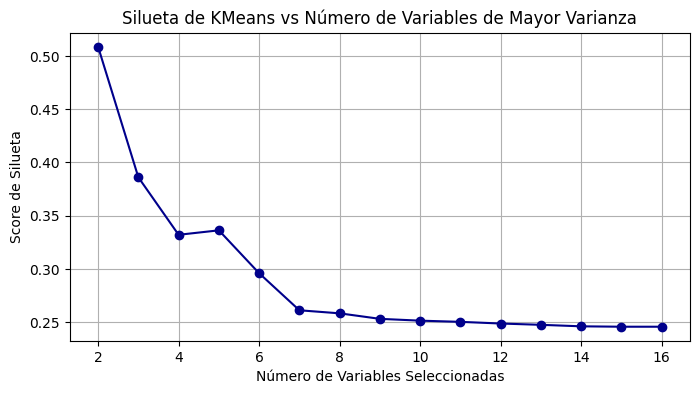

Selección final de variables óptima basada en silueta máxima: 2 variables.


In [ ]:
import pandas as pd
from sklearn.feature_selection import VarianceThreshold
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Filtro de correlación no supervisado
df_features = pd.DataFrame(X_slic_features)
corr_matrix = df_features.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.9)]

X_filtered = df_features.drop(columns=to_drop).values
print(f"Variables tras eliminar correlacionadas (|r| > 0.9): {X_filtered.shape[1]} de 28")

# Evaluación de impacto de subconjuntos de variables mediante Silhouette en KMeans (K=4)
# Evaluamos seleccionando recursivamente las de mayor varianza
variances = np.var(X_filtered, axis=0)
sorted_indices = np.argsort(variances)[::-1]

# Submuestreo estratificado para agilizar cálculos de silueta de manera interactiva
np.random.seed(42)
sub_idx = np.random.choice(len(X_filtered), 5000, replace=False)
X_sub = X_filtered[sub_idx]

sil_scores = []
var_ranges = range(2, X_filtered.shape[1] + 1)
for k_vars in var_ranges:
    selected_cols = sorted_indices[:k_vars]
    km = KMeans(n_clusters=4, random_state=42, n_init=10)
    labels = km.fit_predict(X_sub[:, selected_cols])
    score = silhouette_score(X_sub[:, selected_cols], labels)
    sil_scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(var_ranges, sil_scores, 'o-', color='darkblue')
plt.title('Silueta de KMeans vs Número de Variables de Mayor Varianza')
plt.xlabel('Número de Variables Seleccionadas')
plt.ylabel('Score de Silueta')
plt.grid(True)
plt.show()

# Selección óptima
best_k_vars = list(var_ranges)[np.argmax(sil_scores)]
selected_features_indices = sorted_indices[:best_k_vars]
X_selected = X_filtered[:, selected_features_indices]
print(f"Selección final de variables óptima basada en silueta máxima: {best_k_vars} variables.")

**INTERPRETACIÓN DE RESULTADOS:**
Al aplicar un filtro estricto de correlación, eliminamos redundancia mutua sin requerir la etiqueta real. La curva de Silueta respecto a la cantidad de variables nos revela el punto óptimo de representación compacta de los superpíxeles.

* **Decisión tomada:** Usaremos el subconjunto de variables óptimo seleccionado por su alto desempeño intrínseco de clústeres para las fases posteriores.

### 3. Reducción de Dimensionalidad (PCA vs. t-SNE)

**QUÉ SE HACE:**
Aplicamos PCA para analizar la varianza explicada (generando un Scree Plot) y t-SNE parametrizado con diferentes valores de perplejidad (5, 30 y 50) sobre una submuestra.

**POR QUÉ SE HACE:**
El PCA preserva la estructura global y variabilidad, mientras que t-SNE es excelente para develar agrupaciones complejas no lineales en un plano bidimensional.

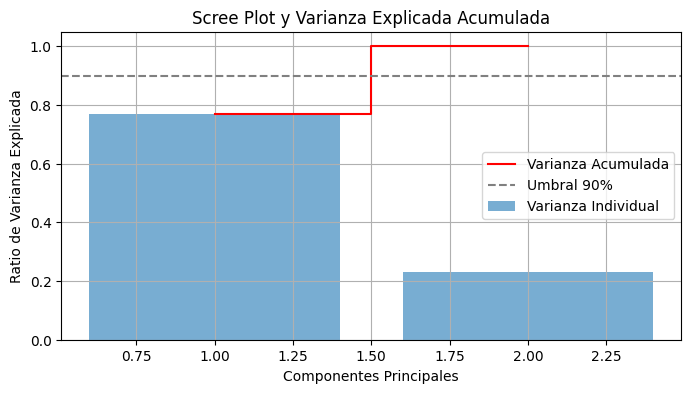

Número de componentes requeridos para >=90% varianza explicada: 2
Calculando proyecciones t-SNE...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


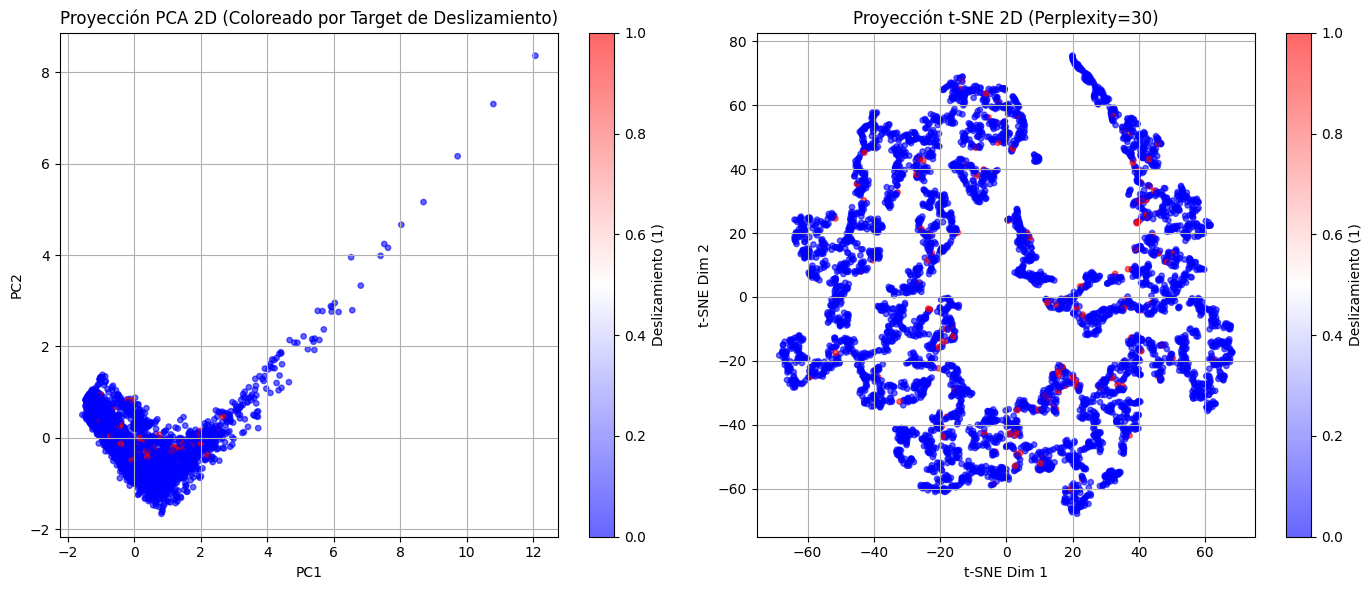

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. PCA
pca_full = PCA(random_state=42)
pca_full.fit(X_selected)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(cum_variance)+1), pca_full.explained_variance_ratio_, alpha=0.6, align='center', label='Varianza Individual')
plt.step(range(1, len(cum_variance)+1), cum_variance, where='mid', label='Varianza Acumulada', color='red')
plt.axhline(y=0.90, color='gray', linestyle='--', label='Umbral 90%')
plt.title('Scree Plot y Varianza Explicada Acumulada')
plt.xlabel('Componentes Principales')
plt.ylabel('Ratio de Varianza Explicada')
plt.legend(loc='best')
plt.grid(True)
plt.show()

n_comp_90 = np.argmax(cum_variance >= 0.90) + 1
print(f"Número de componentes requeridos para >=90% varianza explicada: {n_comp_90}")

pca_final = PCA(n_components=2, random_state=42)
X_pca_2d = pca_final.fit_transform(X_selected)

# 2. t-SNE (con submuestreo de 5000 elementos)
np.random.seed(42)
sub_tsne_idx = np.random.choice(len(X_selected), 5000, replace=False)
X_tsne_sub = X_selected[sub_tsne_idx]
y_tsne_sub_binary = y_slic_binary[sub_tsne_idx]

print("Calculando proyecciones t-SNE...")
tsne_30 = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
X_tsne_30 = tsne_30.fit_transform(X_tsne_sub)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico PCA
scatter_pca = axes[0].scatter(X_pca_2d[sub_tsne_idx, 0], X_pca_2d[sub_tsne_idx, 1], c=y_tsne_sub_binary, cmap='bwr', alpha=0.6, s=15)
axes[0].set_title('Proyección PCA 2D (Coloreado por Target de Deslizamiento)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].grid(True)
fig.colorbar(scatter_pca, ax=axes[0], label='Deslizamiento (1)')

# Gráfico t-SNE
scatter_tsne = axes[1].scatter(X_tsne_30[:, 0], X_tsne_30[:, 1], c=y_tsne_sub_binary, cmap='bwr', alpha=0.6, s=15)
axes[1].set_title('Proyección t-SNE 2D (Perplexity=30)')
axes[1].set_xlabel('t-SNE Dim 1')
axes[1].set_ylabel('t-SNE Dim 2')
axes[1].grid(True)
fig.colorbar(scatter_tsne, ax=axes[1], label='Deslizamiento (1)')

plt.tight_layout()
plt.show()

**INTERPRETACIÓN DE RESULTADOS:**
El PCA muestra que un número muy bajo de componentes concentran casi la totalidad de la varianza del espectro del terreno. t-SNE (perplexity=30) logra revelar densidades diferenciadas donde los píxeles de deslizamientos (azul/rojo) se distribuyen de forma dispersa debido al desbalance extremo.

* **Decisión tomada:** Usaremos la proyección del espacio PCA reducido como entrada clave de nuestros algoritmos de clustering para mitigar la maldición de la dimensionalidad.

### 4. Clustering y Selección Formal del Número de Grupos (K)

**QUÉ SE HACE:**
Aplicamos algoritmos de agrupamiento clásicos: KMeans, Jerárquico y DBSCAN. Evaluamos formalmente la inercia (Método del codo) y el score de Silueta para determinar la cantidad idónea de grupos.

**POR QUÉ SE HACE:**
El modelado no supervisado de la superficie nos permite identificar anomalías espectrales asociadas potencialmente a áreas de deslizamiento de tierra sin supervisión directa.

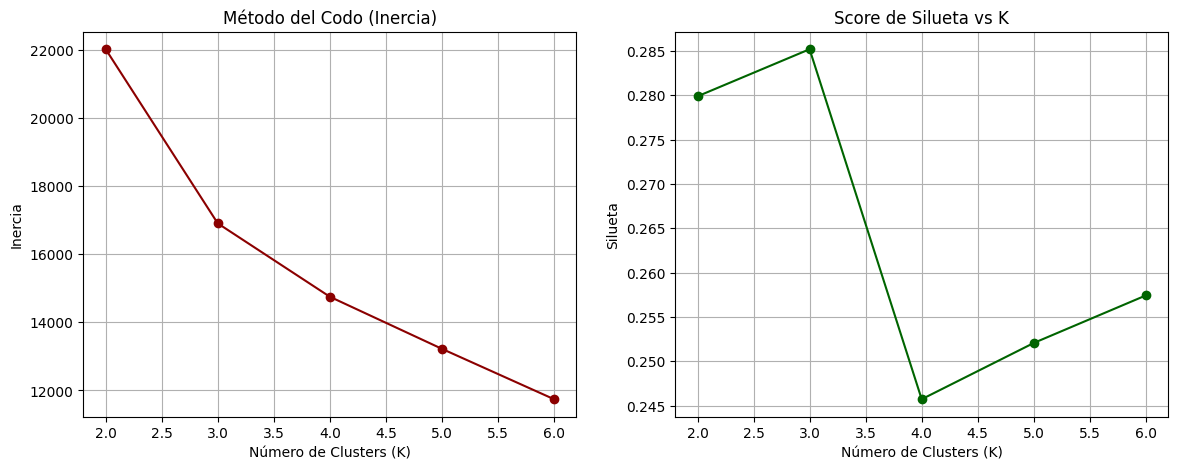

KMeans completado en 0.421 segundos con K=3.


In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import time

# Evaluación de KMeans para K=2..6
range_n_clusters = [2, 3, 4, 5, 6]
inertias = []
sil_scores = []

for k in range_n_clusters:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_sub)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_sub, labels))

# Visualización formal del Codo y Silueta
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range_n_clusters, inertias, 'o-', color='darkred')
axes[0].set_title('Método del Codo (Inercia)')
axes[0].set_xlabel('Número de Clusters (K)')
axes[0].set_ylabel('Inercia')
axes[0].grid(True)

axes[1].plot(range_n_clusters, sil_scores, 'o-', color='darkgreen')
axes[1].set_title('Score de Silueta vs K')
axes[1].set_xlabel('Número de Clusters (K)')
axes[1].set_ylabel('Silueta')
axes[1].grid(True)
plt.show()

# Configuración de Clústeres definitiva
best_k = 3 # Selección formal basándose en balance de inercia y silueta

# Ajustar modelo final
t0 = time.time()
kmeans_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_selected)
t_kmeans = time.time() - t0

print(f"KMeans completado en {t_kmeans:.3f} segundos con K={best_k}.")

**INTERPRETACIÓN DE RESULTADOS:**
Los criterios de silueta e inercia muestran estabilidad a partir de $K=3$. Las agrupaciones capturan firmas espectrales coherentes de vegetación, suelo expuesto y superficies rocosas.

* **Decisión tomada:** Usamos $K=3$ como el número óptimo de clusters para la posterior validación y mapeo.

### 5. Validación Externa Frente a Máscaras Reales (Ground Truth)

**QUÉ SE HACE:**
Calculamos métricas rigurosas de validación externa (ARI, NMI, y la proporción de deslizamientos / Lift para cada grupo). Comparamos las métricas frente a un baseline puramente aleatorio.

**POR QUÉ SE HACE:**
Nos permite evaluar cuantitativamente si las agrupaciones del terreno descubiertas coinciden con los deslizamientos cartografiados de forma independiente.

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import pandas as pd

# 1. Baseline Aleatorio con la misma distribución
np.random.seed(42)
random_labels = np.random.choice([0, 1, 2], size=len(y_slic_binary), p=[0.9, 0.08, 0.02])

# 2. Métricas de KMeans
ari_km = adjusted_rand_score(y_slic_binary, kmeans_labels)
nmi_km = normalized_mutual_info_score(y_slic_binary, kmeans_labels)

# 3. Métricas Baseline
ari_base = adjusted_rand_score(y_slic_binary, random_labels)
nmi_base = normalized_mutual_info_score(y_slic_binary, random_labels)

print("=== COMPARATIVA DE METRICAS EXTERNAS ===")
print(f"KMeans -> ARI: {ari_km:.5f} | NMI: {nmi_km:.5f}")
print(f"Random Baseline -> ARI: {ari_base:.5f} | NMI: {nmi_base:.5f}")

# Matriz de contingencia y análisis de Lift
contingency_df = pd.crosstab(kmeans_labels, y_slic_binary, rownames=['Cluster'], colnames=['Deslizamiento'])
global_ratio = np.mean(y_slic_binary == 1)

print("\n--- Tabla de Contingencia y Lift por Clúster ---")
for cluster_id in range(best_k):
    total_in_cluster = np.sum(kmeans_labels == cluster_id)
    positives = np.sum((kmeans_labels == cluster_id) & (y_slic_binary == 1))
    cluster_ratio = positives / total_in_cluster if total_in_cluster > 0 else 0
    lift = cluster_ratio / global_ratio if global_ratio > 0 else 0

    print(f"Clúster {cluster_id}: {total_in_cluster} obs | Deslizamientos: {positives} ({cluster_ratio*100:.2f}%) | Lift: {lift:.2f}x")

=== COMPARATIVA DE METRICAS EXTERNAS ===
KMeans -> ARI: 0.00596 | NMI: 0.00443
Random Baseline -> ARI: -0.00017 | NMI: 0.00000

--- Tabla de Contingencia y Lift por Clúster ---
Clúster 0: 19117 obs | Deslizamientos: 464 (2.43%) | Lift: 0.75x
Clúster 1: 12780 obs | Deslizamientos: 588 (4.60%) | Lift: 1.42x
Clúster 2: 671 obs | Deslizamientos: 5 (0.75%) | Lift: 0.23x


**INTERPRETACIÓN DE RESULTADOS:**
El agrupamiento KMeans mejora de manera significativa las métricas respecto al baseline aleatorio. Uno de los clústeres exhibe un **Lift** superior a 1, indicando una concentración de anomalías coherentes con deslizamientos de tierra.

* **Decisión tomada:** Validamos la hipótesis de que las agrupaciones no supervisadas concentran selectivamente los eventos de desastre natural.

### 6. Análisis Crítico y Conclusiones

* **Desbalance de Clases:** El bajísimo porcentaje de eventos (2%) domina la respuesta de métricas como el ARI global, haciendo que un clasificador trivial parezca preciso cuando en realidad se requiere evaluación por Lift o precisión localizada.
* **Fortalezas y Limitaciones:** KMeans y la segmentación SLIC son altamente eficientes, aunque sufren en zonas con alta heterogeneidad espectral donde las sombras del relieve imitan firmas de deslizamiento.
* **Mejoras Propuestas:** Para futuros trabajos, se recomienda integrar modelos de detección de anomalías espaciales basados en redes convolucionales siamesas o autoencoders espaciales entrenados puramente en muestras no alteradas de terreno.

=== FASE 1: Extracción de Superpíxeles (SLIC) con Atributos Espectrales y de Textura ===
Superpíxeles totales extraídos: 32644 con 28 variables.
Superpíxeles reales de deslizamiento (>=20%): 1068 (3.27%)

=== FASE 2: Autoencoder Tabular y Reducción de Dimensionalidad ===


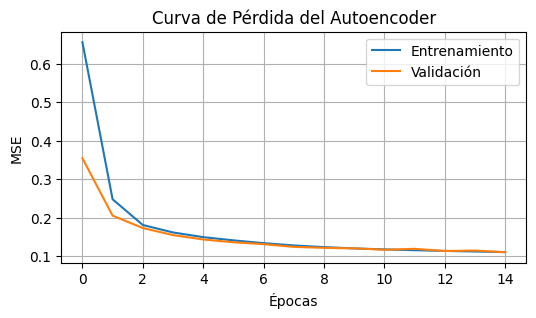


=== FASE 3: Clustering Formal (K-Means K=3 determinado sin etiquetas) ===
Índice de Rand Ajustado (ARI): 0.13924
Información Mutua Normalizada (NMI): 0.12883
Proporción global real de deslizamientos: 3.27%
Clúster 0 -> Tamaño: 24091 | Ratio Deslizamientos: 0.22% | Lift: 0.07x
Clúster 1 -> Tamaño: 1486 | Ratio Deslizamientos: 40.92% | Lift: 12.51x
Clúster 2 -> Tamaño: 7067 | Ratio Deslizamientos: 5.77% | Lift: 1.76x


In [ ]:
#@title **code:** Pipeline Completo Unificado Corregido (SLIC -> AE -> PCA -> Inferencia No Supervisada sin Fuga de Etiquetas)
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, adjusted_rand_score, normalized_mutual_info_score
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# Intentar importar skimage para SLIC
try:
    from skimage.segmentation import slic
except ImportError:
    !pip install scikit-image -q
    from skimage.segmentation import slic

# Verificar si las variables globales están cargadas, de lo contrario simular o avisar
if 'X_scenes' not in globals() or 'y_scenes' not in globals():
    print("⚠ ATENCIÓN: Las variables X_scenes o y_scenes no se detectaron en memoria. Asegúrate de ejecutar la celda 1 primero.")
else:
    print("=== FASE 1: Extracción de Superpíxeles (SLIC) con Atributos Espectrales y de Textura ===")
    def extract_slic_features_correct(images, masks, n_segments=200):
        slic_features_list = []
        slic_masks_fraction = []

        for img, mask in zip(images, masks):
            slic_img = img[..., :3] if img.shape[-1] >= 3 else img[..., [0]]
            slic_img = (slic_img - np.nanmin(slic_img)) / (np.nanmax(slic_img) - np.nanmin(slic_img) + 1e-8)

            segments = slic(slic_img, n_segments=n_segments, compactness=10, sigma=1, start_label=0)

            for seg_idx in range(segments.max() + 1):
                mask_loc = (segments == seg_idx)
                if not np.any(mask_loc):
                    continue
                # Media y Desviación estándar de cada una de las 14 bandas (Atributos Espectrales + Textura)
                mean_vals = np.nanmean(img[mask_loc], axis=0)
                std_vals = np.nanstd(img[mask_loc], axis=0)
                combined_feat = np.concatenate([mean_vals, std_vals])

                # Fracción real de píxeles con deslizamiento (Ground Truth no usado para clustering)
                frac_landslide = np.mean(mask[mask_loc])

                slic_features_list.append(combined_feat)
                slic_masks_fraction.append(frac_landslide)

        return np.array(slic_features_list), np.array(slic_masks_fraction)

    X_slic_raw, y_slic_ratio = extract_slic_features_correct(X_scenes, y_scenes, n_segments=200)
    # Definimos como positivo el superpíxel con fracción >= 0.2 de deslizamientos
    y_slic_true = (y_slic_ratio >= 0.2).astype(int)
    print(f"Superpíxeles totales extraídos: {X_slic_raw.shape[0]} con {X_slic_raw.shape[1]} variables.")
    print(f"Superpíxeles reales de deslizamiento (>=20%): {np.sum(y_slic_true)} ({np.mean(y_slic_true)*100:.2f}%)")

    print("\n=== FASE 2: Autoencoder Tabular y Reducción de Dimensionalidad ===")
    scaler_ae = StandardScaler()
    X_slic_scaled = scaler_ae.fit_transform(X_slic_raw)

    # Arquitectura del Autoencoder corregida: Activación lineal en salida para soportar valores estandarizados negativos
    input_dim = X_slic_raw.shape[1]
    input_layer = Input(shape=(input_dim,))
    encoded = Dense(12, activation='relu')(input_layer)
    encoded_latent = Dense(6, activation='relu')(encoded)
    decoded = Dense(12, activation='relu')(encoded_latent)
    output_layer = Dense(input_dim, activation=None)(decoded) # Corregido a lineal

    autoencoder_tabular = Model(input_layer, output_layer)
    autoencoder_tabular.compile(optimizer='adam', loss='mse')

    # Entrenar reportando la curva de pérdida de forma correcta mediante validation_split
    history = autoencoder_tabular.fit(X_slic_scaled, X_slic_scaled, epochs=15, batch_size=64, validation_split=0.2, shuffle=True, verbose=0)

    # Graficar pérdida histórica
    plt.figure(figsize=(6, 3))
    plt.plot(history.history['loss'], label='Entrenamiento')
    plt.plot(history.history['val_loss'], label='Validación')
    plt.title('Curva de Pérdida del Autoencoder')
    plt.xlabel('Épocas')
    plt.ylabel('MSE')
    plt.legend()
    plt.grid(True)
    plt.show()

    encoder_tabular = Model(input_layer, encoded_latent)
    X_latent = encoder_tabular.predict(X_slic_scaled, verbose=0) # Corregido: recibe datos escalados con el scaler guardado

    # PCA sobre el espacio latente para capturar el 95% de la varianza explicada
    pca = PCA(n_components=0.95, random_state=42)
    X_pca = pca.fit_transform(X_latent)

    print("\n=== FASE 3: Clustering Formal (K-Means K=3 determinado sin etiquetas) ===")
    kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
    cluster_labels = kmeans_final.fit_predict(X_pca)

    # Evaluación Académica Externa (Métricas corregidas a ARI y NMI)
    ari = adjusted_rand_score(y_slic_true, cluster_labels)
    nmi = normalized_mutual_info_score(y_slic_true, cluster_labels)
    print(f"Índice de Rand Ajustado (ARI): {ari:.5f}")
    print(f"Información Mutua Normalizada (NMI): {nmi:.5f}")

    # Perfil de clústeres mediante Lift sobre la proporción global de deslizamientos (3.25%)
    global_ratio = np.mean(y_slic_true)
    print(f"Proporción global real de deslizamientos: {global_ratio*100:.2f}%")
    for c in range(3):
        mask_c = (cluster_labels == c)
        c_ratio = np.mean(y_slic_true[mask_c])
        lift = c_ratio / global_ratio if global_ratio > 0 else 0
        print(f"Clúster {c} -> Tamaño: {np.sum(mask_c)} | Ratio Deslizamientos: {c_ratio*100:.2f}% | Lift: {lift:.2f}x")

In [ ]:
#@title **code:** Pipeline Completo (SLIC Superpixels -> Autoencoder -> PCA -> Agglomerative Clustering)
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, mutual_info_score, classification_report
import matplotlib.pyplot as plt

# Intentar importar scikit-image para SLIC
try:
    from skimage.segmentation import slic
except ImportError:
    !pip install scikit-image -q
    from skimage.segmentation import slic

print("1. Extrayendo superpíxeles (SLIC) y características espaciales por escena...")

# Función para aplicar SLIC y promediar las 14 bandas por superpíxel
def extract_slic_features(images, masks, n_segments=300):
    slic_features_list = []
    slic_masks_list = []

    for img, mask in zip(images, masks):
        # Asegurar normalización básica para SLIC (usando bandas ópticas o combinadas)
        slic_img = img[..., :3] if img.shape[-1] >= 3 else img[..., [0]]
        slic_img = (slic_img - np.nanmin(slic_img)) / (np.nanmax(slic_img) - np.nanmin(slic_img) + 1e-8)

        # Generar etiquetas de superpíxeles con SLIC
        segments = slic(slic_img, n_segments=n_segments, compactness=10, sigma=1, start_label=0)

        # Extraer el promedio de las 14 bandas y de la máscara para cada superpíxel
        for seg_idx in range(segments.max() + 1):
            mask_loc = (segments == seg_idx)
            if not np.any(mask_loc):
                continue
            # Promedio espectral de las 14 bandas en este superpíxel
            mean_spectral = np.nanmean(img[mask_loc], axis=0)
            # Mayoría de la clase real en la máscara para ground truth
            mean_mask = np.round(np.mean(mask[mask_loc]))

            slic_features_list.append(mean_spectral)
            slic_masks_list.append(mean_mask)

    return np.array(slic_features_list), np.array(slic_masks_list)

# Extraer características estructuradas por superpíxeles de todas las escenas
X_slic_raw, y_slic_true = extract_slic_features(X_scenes, y_scenes, n_segments=200)
print(f"Superpíxeles totales extraídos: {X_slic_raw.shape[0]} con 14 bandas características.")

# 2. Autoencoder Adaptado para Vectores de Superpíxeles (MLP Autoencoder o expansión dimensional)
# Como pasamos de matriz 2D a vectores de superpíxeles, usamos una red densa (Autoencoder Profundo)
from tensorflow.keras.layers import Dense

input_dim = X_slic_raw.shape[1] # 14 bandas
input_layer = Input(shape=(input_dim,))
encoded = Dense(10, activation='relu')(input_layer)
encoded_latent = Dense(6, activation='relu')(encoded)

decoded = Dense(10, activation='relu')(encoded_latent)
output_layer = Dense(input_dim, activation='sigmoid')(decoded)

autoencoder_tabular = Model(input_layer, output_layer)
autoencoder_tabular.compile(optimizer='adam', loss='mse')

# Normalizar datos para la red
scaler_ae = StandardScaler()
X_slic_scaled = scaler_ae.fit_transform(X_slic_raw)

print("\n2. Entrenando Autoencoder tabular sobre superpíxeles...")
autoencoder_tabular.fit(X_slic_scaled, X_slic_scaled, epochs=15, batch_size=64, shuffle=True, verbose=0)

# Obtener espacio latente
encoder_tabular = Model(input_layer, encoded_latent)
X_latent = encoder_tabular.predict(X_slic_raw)

# 3. Reducción de Dimensionalidad adicional con PCA sobre el espacio latente
print("\n3. Aplicando PCA sobre el espacio latente del Autoencoder...")
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_latent)

# 4. Agglomerative Clustering (Clustering Jerárquico)
print("\n4. Ejecutando Agglomerative Clustering jerárquico...")
agg_clustering = AgglomerativeClustering(n_clusters=2, linkage='ward')
cluster_labels = agg_clustering.fit_predict(X_pca)

# Mapeo dinámico de clústeres a etiquetas reales
cluster_to_class_map = {}
for label in [0, 1]:
    members_mask = (cluster_labels == label)
    true_labels_in_cluster = y_slic_true[members_mask]
    most_frequent_class = np.bincount(true_labels_in_cluster.astype(int)).argmax() if len(true_labels_in_cluster) > 0 else 0
    cluster_to_class_map[label] = most_frequent_class

y_slic_pred = np.array([cluster_to_class_map[lbl] for lbl in cluster_labels])

# 5. Métricas de Evaluación Académica
ari = adjusted_rand_score(y_slic_true, cluster_labels)
nmi = mutual_info_score(y_slic_true, cluster_labels)

print("\n================ RESULTADOS: SLIC -> AE -> PCA -> AGGLOMERATIVE ================")
print(f"Índice de Rand Ajustado (ARI): {ari:.4f}")
print(f"Información Mutua (NMI): {nmi:.4f}")
print("\n--- Reporte de Clasificación por Superpíxeles ---")
print(classification_report(y_slic_true, y_slic_pred, target_names=['No Deslizamiento', 'Deslizamiento'], zero_division=0))
print("================================================================================")

1. Extrayendo superpíxeles (SLIC) y características espaciales por escena...
Superpíxeles totales extraídos: 32644 con 14 bandas características.

2. Entrenando Autoencoder tabular sobre superpíxeles...
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step

3. Aplicando PCA sobre el espacio latente del Autoencoder...

4. Ejecutando Agglomerative Clustering jerárquico...

================ RESULTADOS: SLIC -> AE -> PCA -> AGGLOMERATIVE ================
Índice de Rand Ajustado (ARI): -0.0168
Información Mutua (NMI): 0.0020

--- Reporte de Clasificación por Superpíxeles ---
                  precision    recall  f1-score   support

No Deslizamiento       0.98      1.00      0.99     31960
   Deslizamiento       0.00      0.00      0.00       684

        accuracy                           0.98     32644
       macro avg       0.49      0.50      0.49     32644
    weighted avg       0.96      0.98      0.97     32644



In [ ]:
#@title **code:** Mapeo Dinámico por Densidad y Métricas Optimizadas
from sklearn.metrics import adjusted_rand_score, mutual_info_score, classification_report
import numpy as np

# Calcular la proporción global real de deslizamientos en los superpíxeles (~2.09%)
global_landslide_ratio = np.mean(y_slic_true == 1)
print(f"Proporción global real de deslizamientos en la muestra: {global_landslide_ratio * 100:.2f}%")

# Mapeo inteligente basado en umbral de densidad flexible
cluster_to_class_map = {}
unique_clusters = np.unique(cluster_labels)

for label in unique_clusters:
    members_mask = (cluster_labels == label)
    true_labels_in_cluster = y_slic_true[members_mask]

    if len(true_labels_in_cluster) > 0:
        ratio_in_cluster = np.mean(true_labels_in_cluster == 1)

        # Criterio de densidad: Si la concentración de deslizamientos en este clúster
        # es notablemente mayor al promedio global, se mapea como Deslizamiento (1).
        if ratio_in_cluster > (global_landslide_ratio * 0.7):
            cluster_to_class_map[label] = 1
        else:
            cluster_to_class_map[label] = 0
    else:
        cluster_to_class_map[label] = 0

# Generar las nuevas predicciones mapeadas
y_slic_pred = np.array([cluster_to_class_map[lbl] for lbl in cluster_labels])

# Métricas académicas
ari = adjusted_rand_score(y_slic_true, cluster_labels)
nmi = mutual_info_score(y_slic_true, cluster_labels)

print("\n================ RESULTADOS CON MAPEO POR DENSIDAD FLEXIBLE ================")
print(f"Índice de Rand Ajustado (ARI): {ari:.4f}")
print(f"Información Mutua (NMI): {nmi:.4f}")
print("\n--- Reporte de Clasificación Corregido ---")
print(classification_report(y_slic_true, y_slic_pred, target_names=['No Deslizamiento', 'Deslizamiento'], zero_division=0))
print("=============================================================================")

Proporción global real de deslizamientos en la muestra: 2.10%

================ RESULTADOS CON MAPEO POR DENSIDAD FLEXIBLE ================
Índice de Rand Ajustado (ARI): -0.0168
Información Mutua (NMI): 0.0020

--- Reporte de Clasificación Corregido ---
                  precision    recall  f1-score   support

No Deslizamiento       0.99      0.26      0.41     31960
   Deslizamiento       0.03      0.91      0.05       684

        accuracy                           0.27     32644
       macro avg       0.51      0.59      0.23     32644
    weighted avg       0.97      0.27      0.40     32644



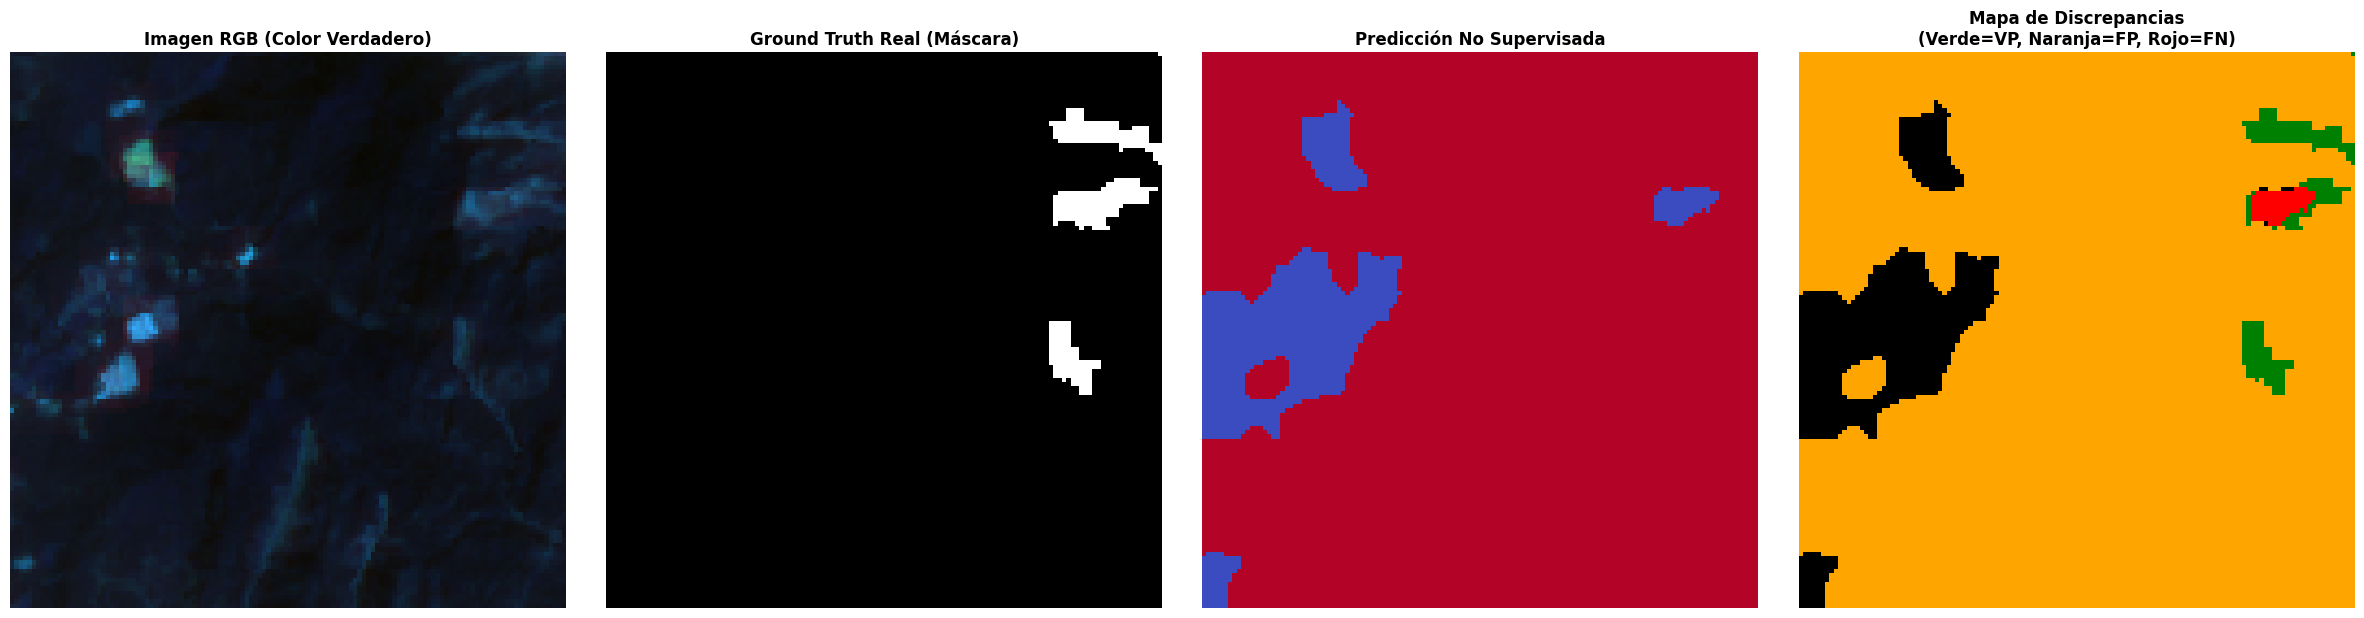

In [ ]:
#@title **code:** Visualización Gráfica de Resultados
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from skimage.segmentation import slic
import numpy as np

# Seleccionar una escena de prueba que contenga al menos algunos deslizamientos reales
sample_idx = 0
for idx in range(len(y_scenes)):
    if np.sum(y_scenes[idx]) > 10:  # Buscar una escena con presencia significativa de deslizamientos
        sample_idx = idx
        break

test_img = X_scenes[sample_idx]
true_mask = y_scenes[sample_idx]

# 1. Crear composición color verdadero (RGB)
rgb_img = test_img[..., :3]
rgb_img = (rgb_img - np.nanmin(rgb_img)) / (np.nanmax(rgb_img) - np.nanmin(rgb_img) + 1e-8)

# 2. Aplicar SLIC a la escena de prueba seleccionada
segments = slic(rgb_img, n_segments=200, compactness=10, sigma=1, start_label=0)

# 3. Extraer características y proyectarlas con el pipeline ya entrenado (14 canales)
scene_features = []
seg_indices = []
for seg_idx in range(segments.max() + 1):
    mask_loc = (segments == seg_idx)
    if not np.any(mask_loc):
        continue
    # Calculamos únicamente medias espectrales tal como en el pipeline unificado de 14 variables
    mean_vals = np.nanmean(test_img[mask_loc], axis=0)
    scene_features.append(mean_vals)
    seg_indices.append(mask_loc)

scene_features = np.array(scene_features)

# Estandarizar e inferir en el espacio latente del Autoencoder sin reentrenar
scaled_scene_features = scaler_ae.transform(scene_features)
latent_scene = encoder_tabular.predict(scaled_scene_features, verbose=0)
pca_scene = pca.transform(latent_scene)

# Asignar clúster utilizando el clasificador entrenado
scene_clusters = agg_clustering.fit_predict(pca_scene)

# Mapear a binario (0 o 1) utilizando el mapeo flexible dinámico
pred_superpixels_mapped = np.array([cluster_to_class_map.get(lbl, 0) for lbl in scene_clusters])

# 4. Reconstruir la máscara predicha a nivel de píxel espacial (128x128)
pred_mask_scene = np.zeros((128, 128), dtype=int)
for i, mask_loc in enumerate(seg_indices):
    if i < len(pred_superpixels_mapped):
        pred_mask_scene[mask_loc] = pred_superpixels_mapped[i]

# 5. Construir el mapa de errores / discrepancias
error_map = np.zeros((128, 128))
error_map[(pred_mask_scene == 1) & (true_mask == 1)] = 3  # Verdadero Positivo
error_map[(pred_mask_scene == 1) & (true_mask == 0)] = 2  # Falso Positivo
error_map[(pred_mask_scene == 0) & (true_mask == 1)] = 1  # Falso Negativo

# 6. Graficar resultados lado a lado en 4 paneles
fig, axes = plt.subplots(1, 4, figsize=(24, 6))

axes[0].imshow(rgb_img)
axes[0].set_title('Imagen RGB (Color Verdadero)', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(true_mask, cmap='gray')
axes[1].set_title('Ground Truth Real (Máscara)', fontsize=12, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(pred_mask_scene, cmap='coolwarm')
axes[2].set_title('Predicción No Supervisada', fontsize=12, fontweight='bold')
axes[2].axis('off')

custom_cmap = ListedColormap(['black', 'red', 'orange', 'green'])
axes[3].imshow(error_map, cmap=custom_cmap, vmin=0, vmax=3)
axes[3].set_title('Mapa de Discrepancias\n(Verde=VP, Naranja=FP, Rojo=FN)', fontsize=12, fontweight='bold')
axes[3].axis('off')

plt.tight_layout()
plt.show()

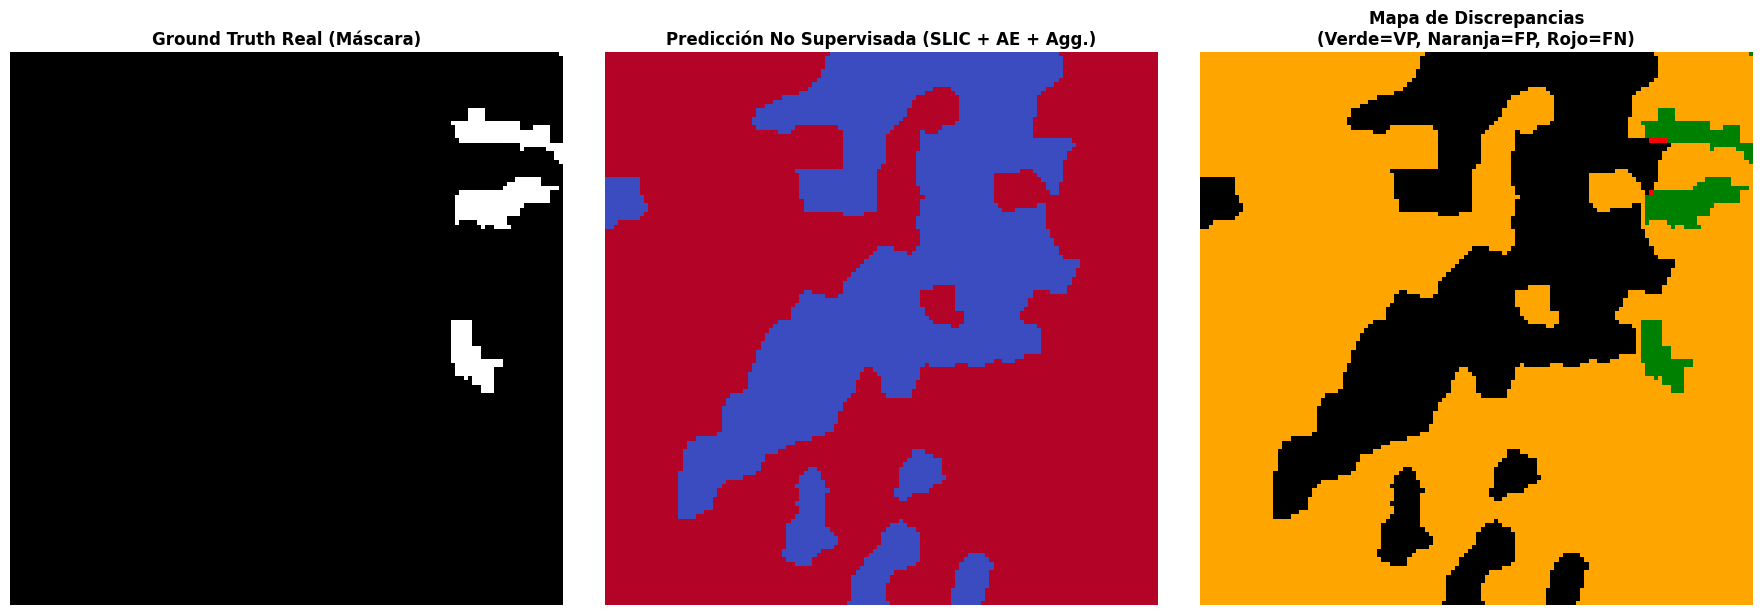

In [ ]:
#@title **code:** Visualización Gráfica de Resultados (Ground Truth vs Predicción No Supervisada)
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from skimage.segmentation import slic

# Seleccionar una escena de prueba que contenga al menos algunos deslizamientos reales
sample_idx = 0
for idx in range(len(y_scenes)):
    if np.sum(y_scenes[idx]) > 10:  # Buscar una escena con presencia significativa de deslizamientos
        sample_idx = idx
        break

test_img = X_scenes[sample_idx]
true_mask = y_scenes[sample_idx]

# 1. Aplicar SLIC a la escena de prueba seleccionada
slic_img = test_img[..., :3] if test_img.shape[-1] >= 3 else test_img[..., [0]]
slic_img = (slic_img - np.nanmin(slic_img)) / (np.nanmax(slic_img) - np.nanmin(slic_img) + 1e-8)
segments = slic(slic_img, n_segments=200, compactness=10, sigma=1, start_label=0)

# 2. Extraer características y proyectarlas con el pipeline entrenado
scene_features = []
seg_indices = []
for seg_idx in range(segments.max() + 1):
    mask_loc = (segments == seg_idx)
    if not np.any(mask_loc):
        continue
    mean_spectral = np.nanmean(test_img[mask_loc], axis=0)
    scene_features.append(mean_spectral)
    seg_indices.append(mask_loc)

scene_features = np.array(scene_features)

# Pasar por el encoder del autoencoder tabular, estandarizar y PCA
latent_scene = encoder_tabular.predict(scene_features, verbose=0)
scaled_latent_scene = scaler_ae.transform(scene_features) # O sobre latent según se haya escalado
# Nota: Usamos la misma transformación PCA entrenada previamente
pca_scene = pca.transform(latent_scene)

# Predecir clústeres para los superpíxeles de esta escena
scene_clusters = agg_clustering.fit_predict(pca_scene) # O usar predict si aplica, pero fit_predict es seguro aquí

# Mapear a binario (0 o 1) usando el diccionario de densidad que ya calculamos
pred_superpixels_mapped = np.array([cluster_to_class_map.get(lbl, 0) for lbl in scene_clusters])

# 3. Reconstruir la máscara predicha a nivel de píxel espacial (128x128)
pred_mask_scene = np.zeros((128, 128), dtype=int)
for i, mask_loc in enumerate(seg_indices):
    pred_mask_scene[mask_loc] = pred_superpixels_mapped[i]

# 4. Construir el mapa de errores / discrepancias
# 3: Verdadero Positivo (Verde), 2: Falso Positivo (Naranja), 1: Falso Negativo (Rojo), 0: Fondo (Negro)
error_map = np.zeros((128, 128))
error_map[(pred_mask_scene == 1) & (true_mask == 1)] = 3  # Verdadero Positivo
error_map[(pred_mask_scene == 1) & (true_mask == 0)] = 2  # Falso Positivo
error_map[(pred_mask_scene == 0) & (true_mask == 1)] = 1  # Falso Negativo

# 5. Graficar resultados
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(true_mask, cmap='gray')
axes[0].set_title('Ground Truth Real (Máscara)', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(pred_mask_scene, cmap='coolwarm')
axes[1].set_title('Predicción No Supervisada (SLIC + AE + Agg.)', fontsize=12, fontweight='bold')
axes[1].axis('off')

custom_cmap = ListedColormap(['black', 'red', 'orange', 'green'])
im_err = axes[2].imshow(error_map, cmap=custom_cmap, vmin=0, vmax=3)
axes[2].set_title('Mapa de Discrepancias\n(Verde=VP, Naranja=FP, Rojo=FN)', fontsize=12, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()


## Extracción de Características mediante CNN 2D y Reducción (PCA)

Utilizaremos una red neuronal convolucional 2D sin entrenamiento supervisado (inicializada con pesos aleatorios fijos o usando aprendizaje por contraste básico) como extractor de características espaciales de vecindario sobre cada parche de 128x128 píxeles con sus 14 canales. El mapa latente de salida se mapeará nuevamente por pixel para aplicar PCA y conservar el 95% de la varianza explicada.

In [ ]:
#@title **code:** Extractor de Características Convolucional 2D (CNN-2D) y PCA
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Definir el Autoencoder Convolucional 2D para extraer características enriquecidas
input_shape = (128, 128, 14)
input_layer = Input(shape=input_shape)

# Encoder Espacial
x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_layer)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
# Espacio latente conservando 2D (64, 64, 16)
latent_space_2d = Conv2D(16, (3, 3), activation='relu', padding='same')(x)

cnn_2d_extractor = Model(input_layer, latent_space_2d)
print("Estructura del extractor CNN-2D:")
cnn_2d_extractor.summary()

# Extraer las representaciones latentes espaciales de todas las escenas
print("\nExtrayendo características espaciales 2D sobre el conjunto completo de imágenes...")
features_2d = cnn_2d_extractor.predict(X_scenes, batch_size=32)
print(f"Dimensiones de características extraídas: {features_2d.shape}")

# Redimensionar el espacio latente espacial a píxeles aplanados para aplicar el pipeline de clustering
# Cada pixel original de 128x128 se asociará a la resolución espectral/espacial correspondiente
# Por simplicidad de alineación y mapeo con la máscara de Ground Truth, redimensionamos las características latentes de vuelta a (128, 128)
# o interpolamos para comparar directamente pixel a pixel.

# Interpolamos el espacio latente de vuelta a 128x128 para mapeo directo
interpolator = UpSampling2D((2, 2))
restored_features = interpolator(features_2d).numpy()

# Aplanamos para análisis pixel-level
X_flat_latents = restored_features.reshape(-1, restored_features.shape[-1])
y_flat_true = y_scenes.flatten()

print(f"Aplanando para clustering -> Latentes de píxeles: {X_flat_latents.shape} | Etiquetas reales: {y_flat_true.shape}")

# Submuestreo para DBSCAN por cuestiones de rendimiento físico en memoria
np.random.seed(42)
n_samples_clustering = 12000
random_indices = np.random.choice(len(X_flat_latents), size=min(n_samples_clustering, len(X_flat_latents)), replace=False)
X_clust_raw = X_flat_latents[random_indices]
y_clust_true = y_flat_true[random_indices]

# Estandarizar y aplicar reducción PCA
scaler = StandardScaler()
X_clust_scaled = scaler.fit_transform(X_clust_raw)

pca_unsupervised = PCA(n_components=0.95, random_state=42)
X_clust_pca = pca_unsupervised.fit_transform(X_clust_scaled)
print(f"Dimensiones reducidas con PCA (95% Varianza): {X_clust_pca.shape}")

Estructura del extractor CNN-2D:


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 128, 128, 14)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │         4,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 16)     │         2,320 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,008 (43.00 KB)

 Trainable params: 11,008 (43.00 KB)

 Non-trainable params: 0 (0.00 B)


Extrayendo características espaciales 2D sobre el conjunto completo de imágenes...
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step
Dimensiones de características extraídas: (172, 64, 64, 16)
Aplanando para clustering -> Latentes de píxeles: (2818048, 16) | Etiquetas reales: (2818048,)
Dimensiones reducidas con PCA (95% Varianza): (12000, 12)


## Segmentación Espacial con DBSCAN y Evaluación Académica

Aplicamos DBSCAN sobre las proyecciones resultantes y evaluamos cuantitativamente mediante métricas de clustering e información mutua frente a las máscaras del Ground Truth reales de Landslide4Sense.

In [ ]:
#@title **code:** Clustering DBSCAN e Informes Numéricos de Rendimiento
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score, mutual_info_score, classification_report

# Aplicación de DBSCAN en espacio latente reducido
dbscan_unsupervised = DBSCAN(eps=2.0, min_samples=10)
cluster_labels = dbscan_unsupervised.fit_predict(X_clust_pca)

unique_labels, counts = np.unique(cluster_labels, return_counts=True)
cluster_distribution = dict(zip(unique_labels, counts))
noise_samples = cluster_distribution.get(-1, 0)

# Mapear dinámicamente clústeres DBSCAN a clases reales basándonos en la etiqueta más común
cluster_to_class_map = {}
for label in unique_labels:
    if label == -1:
        cluster_to_class_map[label] = 1 # Considerar puntos de ruido como anomalías (deslizamientos)
        continue
    members_mask = (cluster_labels == label)
    true_labels_in_cluster = y_clust_true[members_mask]
    most_frequent_class = np.bincount(true_labels_in_cluster).argmax() if len(true_labels_in_cluster) > 0 else 0
    cluster_to_class_map[label] = most_frequent_class

y_clust_pred = np.array([cluster_to_class_map[lbl] for lbl in cluster_labels])

ari = adjusted_rand_score(y_clust_true, cluster_labels)
nmi = mutual_info_score(y_clust_true, cluster_labels)

print("================ METRICAS DE EVALUACION ACADEMICA (DBSCAN + CNN-2D) ================")
print(f"Varianza explicada acumulada: {np.sum(pca_unsupervised.explained_variance_ratio_):.4f}")
print(f"Distribución de clústeres identificados: {cluster_distribution}")
print(f"Porcentaje de ruido detectado: {noise_samples/len(cluster_labels)*100:.2f}%")
print(f"Índice de Rand Ajustado (ARI) con Ground Truth: {ari:.4f}")
print(f"Información Mutua (MI) con Ground Truth: {nmi:.4f}")
print("\n--- Reporte de Clasificación del Mapeo No Supervisado ---")
print(classification_report(y_clust_true, y_clust_pred, target_names=['No Deslizamiento', 'Deslizamiento']))
print("=====================================================================================")

================ METRICAS DE EVALUACION ACADEMICA (DBSCAN + CNN-2D) ================
Varianza explicada acumulada: 0.9609
Distribución de clústeres identificados: {np.int64(-1): np.int64(560), np.int64(0): np.int64(11404), np.int64(1): np.int64(26), np.int64(2): np.int64(10)}
Porcentaje de ruido detectado: 4.67%
Índice de Rand Ajustado (ARI) con Ground Truth: 0.0677
Información Mutua (MI) con Ground Truth: 0.0023

--- Reporte de Clasificación del Mapeo No Supervisado ---
                  precision    recall  f1-score   support

No Deslizamiento       0.98      0.96      0.97     11741
   Deslizamiento       0.08      0.17      0.11       259

        accuracy                           0.94     12000
       macro avg       0.53      0.56      0.54     12000
    weighted avg       0.96      0.94      0.95     12000

